# Degradation as Biomarker or Shortcut? — PART 2: CXR arm (MIDL 2027)
**NIH ChestX-ray14 (patient-grouped train/val/test) -> Kermany pediatric pneumonia (external OOD)** · same pipeline, backbones and arms as Part 1.

**Six backbones, same grid as Part 1.** **Run in a FRESH session.** Inputs: *NIH Chest X-rays*, *Pediatric Pneumonia Chest X-ray*, and the **output of the fundus notebook** (needed for the combined decision-rule figure / difference-in-differences). Internet On, GPU T4.
First run with `SMOKE = True` (cell 1), then `SMOKE = False`.
**Time:** with 5 seeds the CXR grid needs roughly 9-10 h on one T4 - **split it over TWO sessions** (session A: `BACKBONES` = first three, session B: last three; same notebook, same settings). Section 7/8 merge the two outputs when both are mounted as inputs.
**Fundus input:** *Save Version (Commit)* the finished fundus notebook, then *Add Input -> Your Work / Notebook output* in this notebook; Section 8 finds `preds_fundus_<backbone>.npz` there automatically.

**v5 arms (identical to the fundus v5 run, do not change them):** `baseline`, `harness`, `harness_ctrl`, `suppress` (ramped GRL, held-out adversary accuracy logged, eligible-epoch checkpoint selection) on all six backbones; `aug` (mild), `aug_strong`, `harness_brisque` on ResNet-50 only. Table 13 (test-time degradation-vector intervention) and the forensic probes are produced per backbone exactly as in Part 1.

CXR-specific additions: acquisition-protocol confound analysis (AP vs PA view, age), constant-feature pruning (grayscale), explicit prevalence reporting (NIH subsample is ~30% pneumonia by construction vs ~1.3% natural vs ~62% Kermany-test), combined fundus-vs-CXR analysis.

In [1]:
!pip install -q pyiqa timm

import os, sys, glob, json, time, random, warnings, fnmatch, math, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as TF          # NOTE: the features DataFrame is called FD (no more F-shadowing)
import torchvision.transforms as T
from PIL import Image, ImageEnhance, ImageFilter
from scipy import ndimage
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from sklearn.metrics import (roc_auc_score, average_precision_score, cohen_kappa_score,
                             balanced_accuracy_score, accuracy_score)

warnings.filterwarnings('ignore')
def _clip8(z): return np.clip(z, -8, 8)       # guards the probes against (near-)constant feature dimensions blowing up after z-scoring

# =============================== CONFIG ===============================
SMOKE = False        # True = ~15 min end-to-end dry run (ALL backbones, tiny subsets, 1 epoch). RUN THIS FIRST, then set False.
SEEDS = [42, 7, 2024, 11, 99]     # v5: 5 seeds (v4: 3). CXR external AUC varied by up to 0.06 between seeds; more seeds = tighter, seed-aware CIs
EPOCHS = 15
BS = 32
N_WORKERS = 4
TIME_BUDGET_H = 10.5              # no new training run is launched after this many hours (Kaggle session limit = 12 h)

# six backbones from five different families (timm names). Order = priority if the time budget runs out.
BACKBONES = ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224']
#   resnet50 / densenet121 / efficientnet_b0 : CNN with BatchNorm   (residual / dense / depthwise-MBConv)
#   convnext_tiny                            : CNN with LayerNorm (no BatchNorm)
#   vit_small_patch16_224                    : plain transformer (global attention, no BatchNorm)
#   swin_tiny_patch4_window7_224             : hierarchical windowed transformer
# To split the work over TWO Kaggle sessions (recommended if the benchmark below projects > 10 h):
#   session A: BACKBONES = first three, session B: BACKBONES = last three; the final aggregation cell merges both outputs.
LR_BB = {'resnet50': 3e-5, 'convnext_tiny': 3e-5, 'vit_small_patch16_224': 3e-5,
         'densenet121': 5e-5, 'efficientnet_b0': 1e-4, 'swin_tiny_patch4_window7_224': 3e-5}   # fine-tuning LR of the backbone (heads: 1e-3)
AUG_BACKBONES = ['resnet50']      # augmentation arms + the BRISQUE-only harness ablation are run on these backbones only
CORE_ARMS = ['baseline', 'harness', 'harness_ctrl', 'suppress']
#   harness_ctrl = harness architecture fed SHUFFLED degradation vectors (controls for the extra parameters)
EXTRA_ARMS = ['aug', 'aug_strong', 'harness_brisque']
#   aug            = MILD, lesion-safe augmentation (gamma/contrast +-20-25 %, blur & noise applied to 30 % of images and weak) = the fair augmentation baseline
#   aug_strong     = the v3 augmentation (always-on blur sigma up to 2 px + noise) = sensitivity analysis (it erases microaneurysms)
#   harness_brisque= harness that sees ONLY BRISQUE (1 of 11 features): tests whether the benefit comes from the single quality score
ARMS_FOR = {b: CORE_ARMS + (EXTRA_ARMS if b in AUG_BACKBONES else []) for b in BACKBONES}
PROBE_SEEDS_N = 3                 # forensic probes are run on the first N seeds only (cost control)
N_SMOKE = 120                     # images per split in SMOKE mode
LAM = 1.0                         # final GRL strength; it is RAMPED 0 -> LAM during training (DANN schedule), see train_arm
ADV_W = 0.5                       # adversarial loss weight (v3: 1.0 constant -> the ConvNeXt adversary collapsed below chance)
ADV_TOL = 0.10                    # a suppress epoch is 'eligible' for checkpoint selection only if |val adversary acc - 0.20| <= ADV_TOL
SEED = 42
# ======================================================================
if SMOKE:
    SEEDS, EPOCHS, PROBE_SEEDS_N = SEEDS[:1], 1, 1

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
TOP = '/kaggle/working'
WORK = TOP + ('/smoke' if SMOKE else '')
# checkpoints go to /kaggle/temp (NOT saved with the notebook output -> output stays small); fall back to working dir elsewhere
CKPT_ROOT = '/kaggle/temp' if os.path.isdir('/kaggle/temp') else TOP
RES, CKPT, FEAT = f'{WORK}/results', f'{CKPT_ROOT}/ckpt' + ('_smoke' if SMOKE else ''), f'{WORK}/features'
for d in (RES, CKPT, FEAT):
    os.makedirs(d, exist_ok=True)
INPUT = '/kaggle/input'
T0 = time.time()
print('device:', DEVICE, '| SMOKE:', SMOKE, '| seeds:', SEEDS, '| epochs:', EPOCHS)
print('backbones:', {b: ARMS_FOR[b] for b in BACKBONES})

# ---- dataset configuration (CXR arm) ----
TAG = 'cxr'
SRC_TR, SRC_VA, SRC_TE, SRC_EX = 'cxr_train', 'cxr_val', 'cxr_test', 'cxr_kermany'
NAME_ID, NAME_EX, TASK = 'NIH ChestX-ray14', 'Kermany pediatric', 'pneumonia'
N_NEG = 3000                      # negatives sampled from NIH (all pneumonia positives kept)
VAL_FRAC, TEST_FRAC = 0.15, 0.15


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 9.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 100.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.3/226.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1. Data discovery + patient-grouped splits

In [2]:
def walk_input():
    for root, dirs, files in os.walk(INPUT):
        yield root, dirs, files

def find_dirs(patterns):
    hits = []
    for root, dirs, _ in walk_input():
        for d in dirs:
            if any(fnmatch.fnmatch(d.lower(), p) for p in patterns):
                hits.append(os.path.join(root, d))
    return hits

def find_files(patterns):
    hits = []
    for root, _, files in walk_input():
        for f in files:
            if any(fnmatch.fnmatch(f.lower(), p) for p in patterns):
                hits.append(os.path.join(root, f))
    return hits

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
def norm_id(v):
    v = os.path.basename(str(v).strip()).lower()
    v = os.path.splitext(v)[0]
    return ''.join(ch for ch in v if ch.isalnum())

# ---------------- NIH ChestX-ray14 ----------------
nih_csvs = find_files(['data_entry*.csv'])
assert nih_csvs, 'Data_Entry_2017.csv not found - check the NIH dataset name.'
nih_csv = nih_csvs[0]
nih_img_dirs = find_dirs(['images_*'])
assert nih_img_dirs, 'no images_* folders found for NIH.'
nih_map = {}
for d in nih_img_dirs:
    for p in glob.glob(os.path.join(d, '**', '*.*'), recursive=True):
        if p.lower().endswith(IMG_EXT):
            nih_map[norm_id(p)] = p
print('NIH csv:', nih_csv, '| image dirs:', len(nih_img_dirs), '| images:', len(nih_map))
ndf = pd.read_csv(nih_csv)
print('NIH columns:', list(ndf.columns))

def pick_id_col(df, idmap):
    keys = set(idmap.keys()); best_c, best_s = None, 0.0
    for c in df.columns:
        s = float(df[c].astype(str).map(norm_id).isin(keys).mean())
        if s > best_s:
            best_c, best_s = c, s
    return best_c, best_s

idc, rate = pick_id_col(ndf, nih_map)
print(f'NIH id column="{idc}" (match rate={rate:.1%})')
assert idc is not None and rate > 0.5, 'NIH: could not match CSV ids to image files.'
ndf['_id'] = ndf[idc].astype(str).map(norm_id)
ndf = ndf[ndf['_id'].isin(set(nih_map))].drop_duplicates('_id').copy()
ndf['path'] = ndf['_id'].map(nih_map)

lab_col = None
for c in ndf.columns:
    s = ndf[c].astype(str)
    if s.str.contains('pneumonia', case=False).mean() > 0.005 and \
       (s.str.contains(r'\|', regex=True).mean() > 0.01 or (s == 'No Finding').mean() > 0.01):
        lab_col = c; break
print(f'NIH finding-labels column="{lab_col}"')
assert lab_col is not None, 'NIH: could not identify Finding Labels column.'
ndf['label'] = ndf[lab_col].astype(str).str.contains('Pneumonia', case=False).astype(int)
print(f'NIH natural pneumonia prevalence = {ndf.label.mean():.2%} (n={len(ndf)})')

pat_col = next((c for c in ndf.columns if 'patient' in c.lower() and 'id' in c.lower()), None)
ndf['patient'] = ndf[pat_col].astype(str) if pat_col else ndf['_id'].str[:8]
view_col = next((c for c in ndf.columns if 'view' in c.lower() and 'position' in c.lower()), None)
age_col = next((c for c in ndf.columns if 'patient' in c.lower() and 'age' in c.lower()), None)
ndf['view'] = ndf[view_col].astype(str).str.strip() if view_col else 'NA'          # AP vs PA = acquisition protocol
ndf['age'] = pd.to_numeric(ndf[age_col], errors='coerce').clip(0, 100) if age_col else np.nan
print(f'patient col={pat_col} view col={view_col} age col={age_col} | patients={ndf.patient.nunique()}')

# subsample: all positives + N_NEG random negatives (prevalence is therefore ARTIFICIAL, ~30%, vs ~1.3% natural)
pos = ndf[ndf.label == 1]
neg = ndf[ndf.label == 0].sample(min(N_NEG, int((ndf.label == 0).sum())), random_state=SEED)
sub = pd.concat([pos, neg]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print(f'NIH subsample: n={len(sub)}  pos={int(sub.label.sum())} ({sub.label.mean():.1%})')

# patient-grouped 70/15/15 split (no patient appears in two splits)
rng = np.random.default_rng(SEED)
pats = np.array(sorted(sub.patient.unique())); rng.shuffle(pats)
n_p = len(pats); i1, i2 = int(n_p * (1 - VAL_FRAC - TEST_FRAC)), int(n_p * (1 - TEST_FRAC))
g_tr, g_va, g_te = set(pats[:i1]), set(pats[i1:i2]), set(pats[i2:])

def mk(split_name, mask):
    d = sub[mask].copy()
    out = pd.DataFrame({'id': d['_id'].values, 'grade': d['label'].astype(float).values, 'path': d['path'].values,
                        'view': d['view'].values, 'age': d['age'].values, 'patient': d['patient'].values})
    out['source'] = split_name; out['label'] = d['label'].values
    return out.reset_index(drop=True)

tr, va, te = mk(SRC_TR, sub.patient.isin(g_tr)), mk(SRC_VA, sub.patient.isin(g_va)), mk(SRC_TE, sub.patient.isin(g_te))
assert not (set(tr.patient) & set(va.patient)) and not (set(tr.patient) & set(te.patient)) and not (set(va.patient) & set(te.patient))

# ---------------- Kermany pediatric pneumonia (external) ----------------
def find_kermany_root():
    for root, dirs, _ in walk_input():
        low = {d.lower() for d in dirs}
        if os.path.basename(root).lower() in ('train', 'test') and {'normal', 'pneumonia'} <= low:
            return os.path.dirname(root)
    return None
kroot = find_kermany_root()
assert kroot, 'Pediatric Pneumonia dataset not found (expected train|test/{NORMAL,PNEUMONIA}).'
print('Kermany root:', kroot)

def kframe(split, source):
    rows = []
    for cls, lab in [('NORMAL', 0), ('PNEUMONIA', 1)]:
        for p in glob.glob(os.path.join(kroot, split, cls, '**', '*.*'), recursive=True):
            if p.lower().endswith(IMG_EXT):
                rows.append((norm_id(p), p, lab))
    out = pd.DataFrame(rows, columns=['id', 'path', 'label']).drop_duplicates('id')
    out['grade'] = out['label'].astype(float); out['source'] = source
    out['view'] = 'NA'; out['age'] = np.nan; out['patient'] = out['id']
    return out[['id', 'grade', 'path', 'view', 'age', 'patient', 'source', 'label']].reset_index(drop=True)

me = kframe('test', SRC_EX)
assert len(me) > 100, 'Kermany test set looks too small - check folder layout.'

if SMOKE:
    def _sub(d, n=N_SMOKE):
        return pd.concat([g.head(n // 2) for _, g in d.groupby('label')]).reset_index(drop=True)
    tr, va, te, me = _sub(tr), _sub(va), _sub(te), _sub(me)
aud = None
for name, d in [('train', tr), ('val', va), ('test', te), ('kermany', me)]:
    print(f'{name:8s} n={len(d):5d}  pos_rate={d.label.mean():.3f}')
print('NOTE: prevalence shift NIH-subsample ~%.0f%% -> Kermany-test %.0f%% (natural NIH prevalence %.1f%%).'
      % (100 * tr.label.mean(), 100 * me.label.mean(), 100 * ndf.label.mean()))


NIH csv: /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv | image dirs: 12 | images: 112120
NIH columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']
NIH id column="Image Index" (match rate=100.0%)
NIH finding-labels column="Finding Labels"
NIH natural pneumonia prevalence = 1.28% (n=112120)
patient col=Patient ID view col=View Position age col=Patient Age | patients=30805
NIH subsample: n=4431  pos=1431 (32.3%)
Kermany root: /kaggle/input/datasets/andrewmvd/pediatric-pneumonia-chest-xray/Pediatric Chest X-ray Pneumonia
train    n= 3092  pos_rate=0.323
val      n=  660  pos_rate=0.339
test     n=  679  pos_rate=0.308
kermany  n=  624  pos_rate=0.625
NOTE: prevalence shift NIH-subsample ~32% -> Kermany-test 62% (natural NIH prevalence 1.3%).


## 1b. Image bank (decode once)

In [3]:
# ---- decode every image ONCE into a 256x256 uint8 array bank (RAM). Training then needs no disk/JPEG decoding. ----
IMG_SIZE = 256
def load_resized(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

_frames = [tr, va, te, me] + ([aud] if aud is not None else [])
BANK_PATHS = list(dict.fromkeys(pd.concat(_frames)['path'].tolist()))
PATH2ROW = {p: i for i, p in enumerate(BANK_PATHS)}
t0 = time.time()
BANK = np.empty((len(BANK_PATHS), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(8) as pool:
    for i, a in enumerate(pool.map(load_resized, BANK_PATHS)):
        BANK[i] = a
        if i % 500 == 0:
            print(f'  bank {i}/{len(BANK_PATHS)}', end='\r')
print(f'image bank: {BANK.shape}  {BANK.nbytes/1e9:.2f} GB  ({time.time()-t0:.0f}s)')


image bank: (5055, 256, 256, 3)  0.99 GB  (40s)


## 2. Degradation features

In [4]:
all_df = pd.concat([tr, va, te, me], ignore_index=True)
all_df.to_csv(f'{FEAT}/frames.csv', index=False)
print('TOTAL images:', len(all_df))

import pyiqa
ALL_FEATS = ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'colorfulness',
             'dark_channel', 'rms_contrast', 'dyn_range']

def _load_full(p):
    return Image.open(p).convert('RGB')

class DegradationExtractor:
    def __init__(self, device):
        self.device = device
        self.iqa = {m: pyiqa.create_metric(m, device=device) for m in ['brisque', 'niqe', 'piqe', 'musiq']}
    @staticmethod
    def _t(img, size=512):
        img = img.resize((size, size), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.
    def handcrafted(self, img):
        a = np.asarray(img.resize((256, 256), Image.BICUBIC)).astype(np.float32) / 255.
        g = a.mean(axis=2)
        blur = float(ndimage.laplace(g).var())
        r, gg, b = a[..., 0], a[..., 1], a[..., 2]
        rg, yb = r - gg, 0.5 * (r + gg) - b
        colorfulness = float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))
        sw = np.lib.stride_tricks.sliding_window_view(g, (15, 15))
        dark = float(sw.min(axis=(-1, -2)).mean())
        return dict(blur=blur, lum_mean=float(g.mean()), lum_std=float(g.std()), colorfulness=colorfulness,
                    dark_channel=dark, rms_contrast=float(g.std()),
                    dyn_range=float(np.percentile(g, 99) - np.percentile(g, 1)))
    @torch.no_grad()
    def extract(self, df, batch=16):
        rows, paths = [], df['path'].tolist()
        with ThreadPoolExecutor(8) as pool:                       # threaded decoding of the full-res images
            for i in range(0, len(paths), batch):
                imgs = list(pool.map(_load_full, paths[i:i + batch]))
                t = torch.stack([self._t(im) for im in imgs]).to(self.device)
                sc = {m: self.iqa[m](t).flatten().cpu().numpy() for m in self.iqa}
                for j, im in enumerate(imgs):
                    row = {m: float(sc[m][j]) for m in sc}
                    row.update(self.handcrafted(im)); rows.append(row)
                if (i // batch) % 25 == 0:
                    print(f'  {min(i + batch, len(paths))}/{len(paths)}', end='\r')
        return pd.concat([df.reset_index(drop=True).copy(), pd.DataFrame(rows)], axis=1)

ext = DegradationExtractor(DEVICE)
feat_frames = []
for name, d in [('train', tr), ('val', va), ('test', te), ('external', me)]:
    cache = f'{FEAT}/{name}_degradation.csv'
    f = pd.read_csv(cache, dtype={'id': str, 'path': str, 'patient': str}) if os.path.exists(cache) else None
    ok = (f is not None and len(f) == len(d) and set(['id', 'source', 'label', 'grade', 'path'] + ALL_FEATS).issubset(f.columns)
          and not f['label'].isna().any() and f['id'].astype(str).tolist() == d['id'].astype(str).tolist())
    if ok:
        print(f'{name}: loaded cache ({len(f)} rows)')
    else:
        print(f'{name}: extracting {len(d)} images (cache missing/stale)...')
        f = ext.extract(d); f.to_csv(cache, index=False)
    feat_frames.append(f)
del ext; torch.cuda.empty_cache()
FD = pd.concat(feat_frames, ignore_index=True)
FD.to_csv(f'{FEAT}/all_degradation.csv', index=False)
print('features done:', FD.shape)

# drop features that are constant on the TRAIN split (e.g. colorfulness on grayscale chest X-rays)
_sd = FD.loc[FD.source == SRC_TR, ALL_FEATS].std()
FEATS = [f for f in ALL_FEATS if _sd[f] > 1e-6]
if len(FEATS) < len(ALL_FEATS):
    print('dropped constant-on-train degradation features:', [f for f in ALL_FEATS if f not in FEATS])
print('degradation features used (%d): %s' % (len(FEATS), FEATS))
assert not FD[FEATS].isna().any().any(), 'NaN in degradation features - inspect extraction.'


TOTAL images: 5055
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 545kB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 14.0MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/musiq_koniq_ckpt-e95806b9.pth" to /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth



100%|██████████| 104M/104M [00:01<00:00, 82.4MB/s]


Loading pretrained model MUSIQ from /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth
train: extracting 3092 images (cache missing/stale)...
val: extracting 660 images (cache missing/stale)...
test: extracting 679 images (cache missing/stale)...
external: extracting 624 images (cache missing/stale)...
features done: (5055, 19)
dropped constant-on-train degradation features: ['colorfulness']
degradation features used (10): ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'dark_channel', 'rms_contrast', 'dyn_range']


## 3. Figure 1

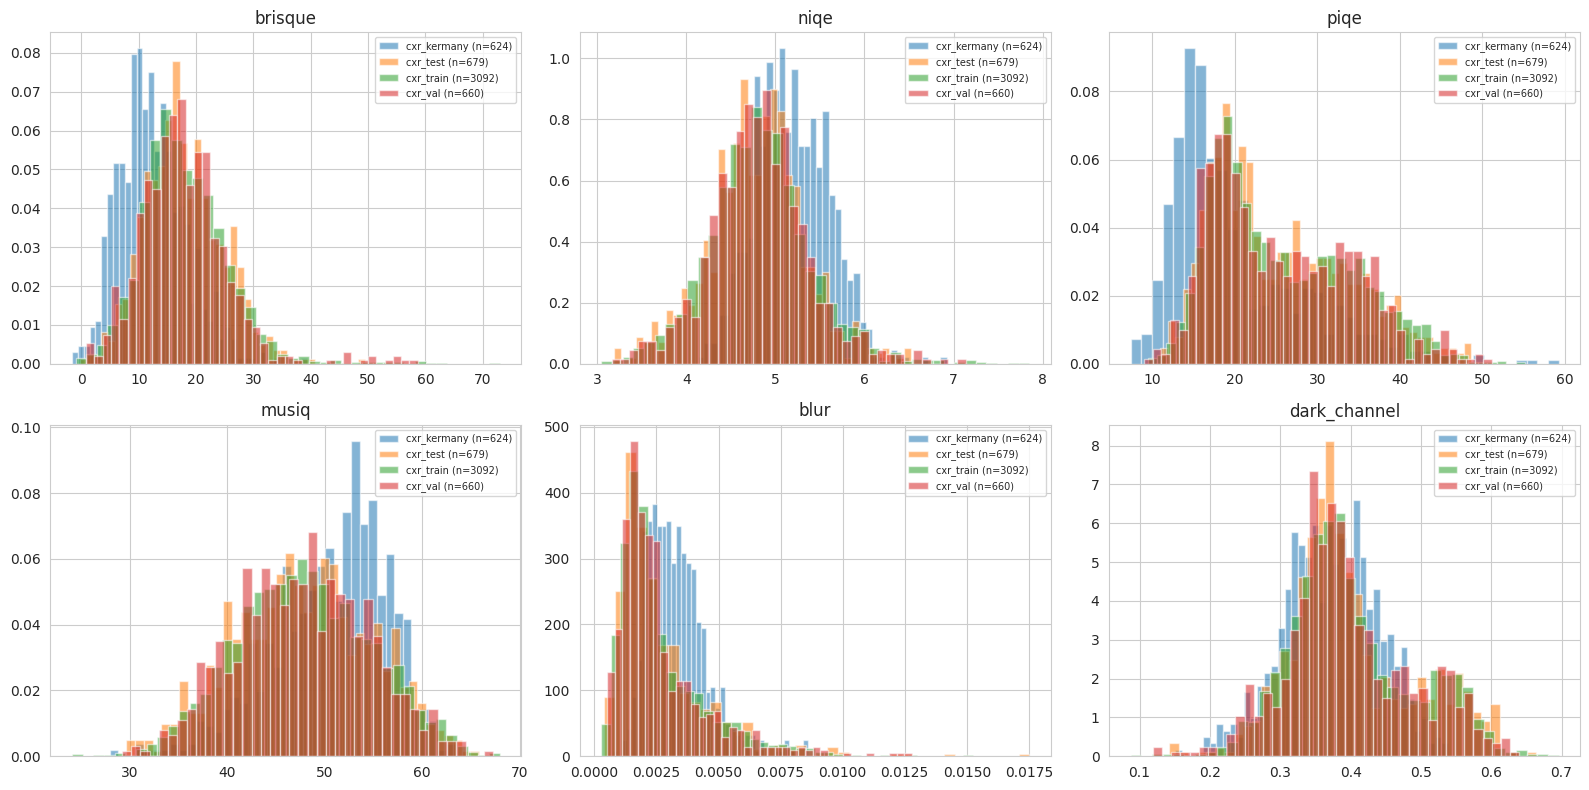

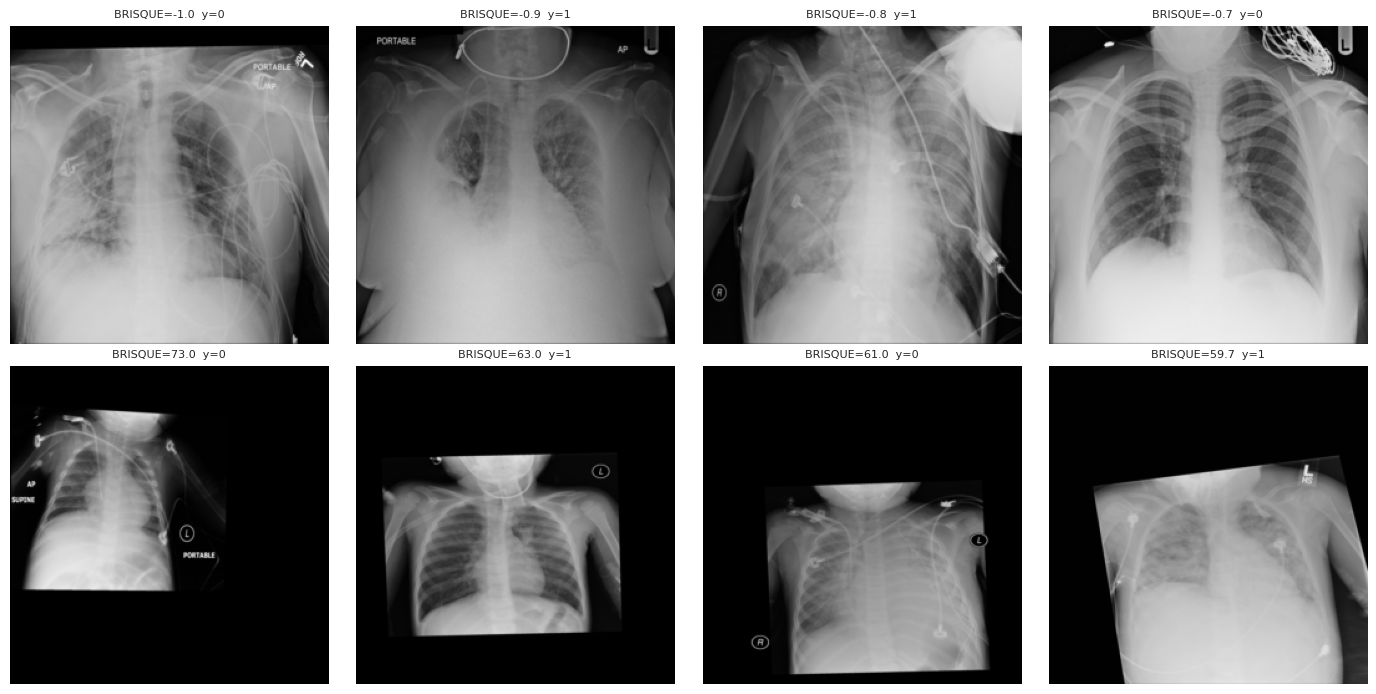

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, ft in zip(axes.ravel(), ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'dark_channel']):
    for src, d in FD.groupby('source'):
        ax.hist(d[ft], bins=40, alpha=0.55, label=f'{src} (n={len(d)})', density=True)
    ax.set_title(ft); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{RES}/fig1_degradation_distributions_{TAG}.png', dpi=200); plt.show()

tr_f = FD[FD.source == SRC_TR]
ex = pd.concat([tr_f.nsmallest(4, 'brisque'), tr_f.nlargest(4, 'brisque')])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), ex.iterrows()):
    ax.imshow(BANK[PATH2ROW[r['path']]]); ax.axis('off')
    ax.set_title(f"BRISQUE={r['brisque']:.1f}  y={int(r['label'])}", fontsize=8)
plt.tight_layout(); plt.savefig(f'{RES}/fig1b_extremes_{TAG}.png', dpi=200); plt.show()


## 4. Probe study + acquisition-protocol confound analysis

=== probe diagnostics ===
FD source counts: {'cxr_train': 3092, 'cxr_test': 679, 'cxr_val': 660, 'cxr_kermany': 624}
negative controls ~0.5 ? True (if False, STOP: the probe pipeline leaks)
                                                                      probe  value     sd         note
                                       NIH ChestX-ray14 5-fold AUC - LogReg 0.6211 0.0123             
                                          NIH ChestX-ray14 5-fold AUC - GBM 0.5895 0.0127             
         NIH ChestX-ray14 5-fold AUC - pyiqa-only (BRISQUE/NIQE/PIQE/MUSIQ) 0.5073 0.0268             
                             NIH ChestX-ray14 5-fold AUC - handcrafted-only 0.6125 0.0129             
                                   NEG CONTROL per-column shuffle (10 reps) 0.4930 0.0266 must be ~0.5
                                      NEG CONTROL per-row shuffle (10 reps) 0.4944 0.0170 must be ~0.5
Kermany pediatric external AUC - LogReg (trained on NIH ChestX-ray14 train) 0.7671    NaN

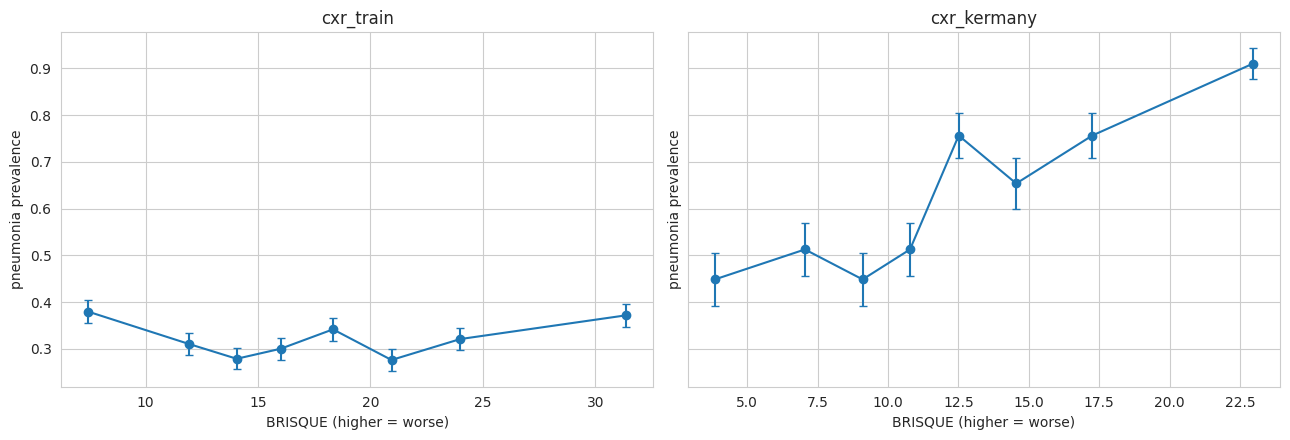

In [6]:
print('=== probe diagnostics ===')
print('FD source counts:', FD.source.value_counts().to_dict())
tr_mask = (FD.source.values == SRC_TR); ex_mask = (FD.source.values == SRC_EX)
va_mask = (FD.source.values == SRC_VA); te_mask = (FD.source.values == SRC_TE)
assert tr_mask.sum() > (50 if SMOKE else 500) and ex_mask.sum() > (50 if SMOKE else 100), 'too few train/external rows in FD.'
assert not np.isnan(FD.label.values).any()
ytr = FD.label.values[tr_mask].astype(int); yex = FD.label.values[ex_mask].astype(int)

# z-score with TRAIN statistics only
mu_tr, sd_tr = FD.loc[tr_mask, FEATS].mean(), FD.loc[tr_mask, FEATS].std().replace(0, 1)
X = ((FD[FEATS] - mu_tr) / sd_tr).values.astype(np.float64)

def cv_auc(Xm, y, model_fn, n_splits=5, seed=SEED):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    aucs = []
    for a, b in skf.split(Xm, y):
        m = model_fn(); m.fit(Xm[a], y[a])
        aucs.append(roc_auc_score(y[b], m.predict_proba(Xm[b])[:, 1]))
    return float(np.mean(aucs)), float(np.std(aucs))
LR = lambda: LogisticRegression(max_iter=3000)
GB = lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED)

probe_rows = []
def add_probe(name, mean, sd=None, note=''):
    probe_rows.append({'probe': name, 'value': round(float(mean), 4), 'sd': (None if sd is None else round(float(sd), 4)), 'note': note})

# --- real probes (disease from degradation features ALONE) ---
add_probe(f'{NAME_ID} 5-fold AUC - LogReg', *cv_auc(X[tr_mask], ytr, LR))
add_probe(f'{NAME_ID} 5-fold AUC - GBM', *cv_auc(X[tr_mask], ytr, GB))
PYIQA_F = [f for f in ['brisque', 'niqe', 'piqe', 'musiq'] if f in FEATS]
HC_F = [f for f in FEATS if f not in PYIQA_F]
for nm, fl in [('pyiqa-only (BRISQUE/NIQE/PIQE/MUSIQ)', PYIQA_F), ('handcrafted-only', HC_F)]:
    ix = [FEATS.index(f) for f in fl]
    add_probe(f'{NAME_ID} 5-fold AUC - {nm}', *cv_auc(X[:, ix][tr_mask], ytr, LR))

# --- negative controls: 10 independent repeats each, must all be ~0.5 ---
col_aucs, row_aucs = [], []
for r in range(10):
    g = np.random.default_rng(1000 + r)
    Xc = X[tr_mask].copy()
    for j in range(Xc.shape[1]):
        Xc[:, j] = Xc[g.permutation(len(Xc)), j]                       # per-COLUMN shuffle
    col_aucs.append(cv_auc(Xc, ytr, LR, seed=r)[0])
    Xr = X[tr_mask][np.random.default_rng(2000 + r).permutation(int(tr_mask.sum()))]   # per-ROW shuffle
    row_aucs.append(cv_auc(Xr, ytr, LR, seed=r)[0])
add_probe('NEG CONTROL per-column shuffle (10 reps)', np.mean(col_aucs), np.std(col_aucs), 'must be ~0.5')
add_probe('NEG CONTROL per-row shuffle (10 reps)', np.mean(row_aucs), np.std(row_aucs), 'must be ~0.5')
ctrl_ok = abs(np.mean(col_aucs) - 0.5) < 0.04 and abs(np.mean(row_aucs) - 0.5) < 0.04
print('negative controls ~0.5 ?', ctrl_ok, '(if False, STOP: the probe pipeline leaks)')

# --- external transfer (probe trained on TRAIN only) ---
deg_lr = LogisticRegression(max_iter=3000).fit(X[tr_mask], ytr)
deg_gb = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(X[tr_mask], ytr)
add_probe(f'{NAME_EX} external AUC - LogReg (trained on {NAME_ID} train)', roc_auc_score(yex, deg_lr.predict_proba(X[ex_mask])[:, 1]))
add_probe(f'{NAME_EX} external AUC - GBM', roc_auc_score(yex, deg_gb.predict_proba(X[ex_mask])[:, 1]))
# sign-flip check on the headline degradation measure
add_probe(f'{NAME_EX} external AUC - BRISQUE alone (raw sign)', roc_auc_score(yex, FD.loc[ex_mask, 'brisque']))
add_probe(f'{NAME_ID} train AUC - BRISQUE alone (raw sign)', roc_auc_score(ytr, FD.loc[tr_mask, 'brisque']))

# degradation-only classifier scores (used later as the "deg_only" reference arm)
DEG_SCORE = {'va': deg_lr.predict_proba(X[va_mask])[:, 1], 'te': deg_lr.predict_proba(X[te_mask])[:, 1],
             'ex': deg_lr.predict_proba(X[ex_mask])[:, 1]}

def save_probe_table():
    pt = pd.DataFrame(probe_rows); pt.to_csv(f'{RES}/table1_probe_{TAG}.csv', index=False)
    return pt
print(save_probe_table().to_string(index=False))

# --- univariate association per feature: does the SIGN / strength transfer? ---
uni = []
for f in FEATS:
    uni.append({'feature': f, f'AUC_{SRC_TR}': roc_auc_score(ytr, FD.loc[tr_mask, f]),
                f'AUC_{SRC_EX}': roc_auc_score(yex, FD.loc[ex_mask, f])})
uni = pd.DataFrame(uni)
uni['sign_flip'] = (uni.iloc[:, 1] - 0.5) * (uni.iloc[:, 2] - 0.5) < 0
print(uni.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
uni.to_csv(f'{RES}/table1b_univariate_{TAG}.csv', index=False)

# --- mechanism figure: prevalence vs BRISQUE ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, src in zip(axes, [SRC_TR, SRC_EX]):
    d = FD[FD.source == src].copy()
    d['bin'] = pd.qcut(d['brisque'], 8, duplicates='drop')
    g = d.groupby('bin', observed=True).agg(prev=('label', 'mean'), n=('label', 'size'), brisque=('brisque', 'mean'))
    ax.errorbar(g['brisque'], g['prev'], yerr=np.sqrt(np.clip(g['prev'] * (1 - g['prev']) / g['n'], 0, None)), marker='o', capsize=3)
    ax.set_title(src); ax.set_xlabel('BRISQUE (higher = worse)'); ax.set_ylabel(f'{TASK} prevalence')
plt.tight_layout(); plt.savefig(f'{RES}/fig2_prevalence_vs_degradation_{TAG}.png', dpi=200); plt.show()


In [7]:
# --- CXR-only: acquisition-protocol confound (AP vs PA view) and age ---
dtr = FD[tr_mask].copy()
print('prevalence by view position (NIH train):'); print(dtr.groupby('view').label.agg(['mean', 'size']).round(3).to_string())
view_ok = dtr['view'].isin(['AP', 'PA']).values
if view_ok.sum() > 100 and dtr['view'][view_ok].nunique() == 2:
    is_ap = (dtr['view'].values[view_ok] == 'AP').astype(int)
    add_probe('NIH: AUC predicting pneumonia from VIEW alone (AP=1)', roc_auc_score(dtr['label'].values[view_ok], is_ap),
              note='acquisition-protocol shortcut strength')
    add_probe('NIH: AUC predicting VIEW (AP vs PA) from degradation features', *cv_auc(X[tr_mask][view_ok], is_ap, LR),
              note='degradation encodes the acquisition protocol')
    for v in ['AP', 'PA']:
        m = (dtr['view'].values == v)
        if m.sum() > 100 and 0 < dtr['label'].values[m].sum() < m.sum():
            add_probe(f'NIH: degradation->pneumonia AUC WITHIN {v} only', *cv_auc(X[tr_mask][m], dtr['label'].values[m].astype(int), LR),
                      note='association left after fixing the protocol')
age_ok = dtr['age'].notna().values
if age_ok.sum() > 100:
    add_probe('NIH: Spearman(BRISQUE, age)', spearmanr(dtr['brisque'].values[age_ok], dtr['age'].values[age_ok])[0])
    add_probe('NIH: AUC predicting pneumonia from AGE alone', roc_auc_score(dtr['label'].values[age_ok], dtr['age'].values[age_ok]))
print(save_probe_table().tail(8).to_string(index=False))


prevalence by view position (NIH train):
       mean  size
view             
AP    0.398  1397
PA    0.261  1695
                                                        probe   value     sd                                         note
    Kermany pediatric external AUC - BRISQUE alone (raw sign)  0.6765    NaN                                             
        NIH ChestX-ray14 train AUC - BRISQUE alone (raw sign)  0.5022    NaN                                             
         NIH: AUC predicting pneumonia from VIEW alone (AP=1)  0.5777    NaN       acquisition-protocol shortcut strength
NIH: AUC predicting VIEW (AP vs PA) from degradation features  0.9714 0.0047 degradation encodes the acquisition protocol
               NIH: degradation->pneumonia AUC WITHIN AP only  0.6021 0.0216   association left after fixing the protocol
               NIH: degradation->pneumonia AUC WITHIN PA only  0.5699 0.0193   association left after fixing the protocol
                                 

## 5. Models — six backbones × arms × seeds

In [8]:
# ---------------- degradation buckets + normalisation constants: TRAIN split only ----------------
qs = np.quantile(FD.loc[tr_mask, 'brisque'], np.linspace(0, 1, 6))
FD['deg_bucket'] = np.clip(np.digitize(FD['brisque'], qs[1:-1]), 0, 4).astype(int)
deg_z_mu = FD.loc[tr_mask, FEATS].mean().values.astype(np.float32)
deg_z_sd = FD.loc[tr_mask, FEATS].std().replace(0, 1).values.astype(np.float32)

import timm
BB = BACKBONES[0]                      # current backbone (global; every loop below sets it)
FEAT_DIM, NORM, train_tf, eval_tf, aug_train_tf, aug_strong_tf = None, None, None, None, None, None

class RandomGamma:
    def __init__(self, lo=0.65, hi=1.5): self.lo, self.hi = lo, hi
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32) / 255.
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        return Image.fromarray((np.power(a, g) * 255).astype(np.uint8))
class RandomNoise:
    def __init__(self, lo=2, hi=12, p=1.0): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        a = np.asarray(img).astype(np.float32)
        a += np.random.normal(0, random.uniform(self.lo, self.hi), a.shape)
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
class RandomBlur:
    def __init__(self, lo=0.5, hi=2.0, p=1.0): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        return img.filter(ImageFilter.GaussianBlur(random.uniform(self.lo, self.hi)))
class RandomContrast:
    def __init__(self, lo=0.6, hi=1.4): self.lo, self.hi = lo, hi
    def __call__(self, img):
        return ImageEnhance.Contrast(img).enhance(random.uniform(self.lo, self.hi))
def set_backbone(name):
    """Switch the global backbone: feature dim and the normalisation constants come from the model's own pretrained config
    (e.g. the ViT checkpoint expects mean=std=0.5, ImageNet CNNs expect the ImageNet statistics)."""
    global BB, FEAT_DIM, NORM, train_tf, eval_tf, aug_train_tf, aug_strong_tf
    BB = name
    m = timm.create_model(name, pretrained=False, num_classes=0)
    FEAT_DIM = int(m.num_features); cfg = m.pretrained_cfg; del m
    NORM = T.Normalize(list(cfg['mean']), list(cfg['std']))
    train_tf = T.Compose([T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    eval_tf = T.Compose([T.CenterCrop(224), T.ToTensor(), NORM])
    aug_strong_tf = T.Compose([RandomGamma(), RandomContrast(), RandomBlur(), RandomNoise(),
                               T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    aug_train_tf = T.Compose([RandomGamma(0.8, 1.25), RandomContrast(0.8, 1.2), RandomBlur(0.3, 0.7, p=0.3), RandomNoise(1, 4, p=0.3),
                              T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    print(f'[backbone] {name}: feat_dim={FEAT_DIM} mean={tuple(round(x,3) for x in cfg["mean"])} std={tuple(round(x,3) for x in cfg["std"])}')

class DS(torch.utils.data.Dataset):
    """Reads pixels from the in-RAM BANK. deg_perm (optional) = fixed permutation used ONLY by harness_ctrl:
    the image at row i is paired with the degradation vector of row perm[i] (breaks the image<->degradation link)."""
    def __init__(self, df, tf, deg_perm=None):
        df = df.reset_index(drop=True)
        self.rows = np.array([PATH2ROW[p] for p in df['path']]); self.y = df['label'].values.astype(np.int64)
        if all(f in df.columns for f in FEATS):
            D = (df[FEATS].values.astype(np.float32) - deg_z_mu) / deg_z_sd
        else:
            D = np.zeros((len(df), len(FEATS)), np.float32)           # frames without features (audit set; baseline only)
        self.deg = torch.from_numpy(D.astype(np.float32))
        self.bkt = df['deg_bucket'].values.astype(np.int64) if 'deg_bucket' in df.columns else np.zeros(len(df), np.int64)
        self.tf, self.perm = tf, deg_perm
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        img = self.tf(Image.fromarray(BANK[self.rows[i]]))
        j = int(self.perm[i]) if self.perm is not None else i
        return img, self.y[i], self.deg[j], self.bkt[i]

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

def make_model(mode, pretrained=True):
    bb = timm.create_model(BB, pretrained=pretrained, num_classes=0).to(DEVICE)
    D, FD_ = len(FEATS), FEAT_DIM; ph = None
    if mode in ('baseline', 'aug', 'aug_strong'):
        head = nn.Linear(FD_, 2).to(DEVICE); extra = [head]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    elif mode in ('harness', 'harness_ctrl'):
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(FD_ + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'harness_brisque':
        mask = torch.zeros(D, device=DEVICE); mask[FEATS.index('brisque')] = 1.0         # only BRISQUE reaches the degradation MLP
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(FD_ + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg * mask)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'suppress':
        head = nn.Linear(FD_, 2).to(DEVICE)
        ph = nn.Sequential(nn.Linear(FD_, 256), nn.ReLU(), nn.Linear(256, 5)).to(DEVICE); extra = [head, ph]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    else:
        raise ValueError(mode)
    return bb, fwd, extra, ph

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def _loader(ds, bs, shuffle, drop_last=False, persistent=True):
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=N_WORKERS, pin_memory=True,
                                       drop_last=drop_last, persistent_workers=persistent and N_WORKERS > 0)

CKPT_FMT = 3        # {'fmt','bb','extra','val_auc'}: backbone AND all heads (the old backbone-only format is rejected)
def ckpt_path(mode, seed, bb=None): return f'{CKPT}/{bb or BB}_{mode}_s{seed}.pt'
def ckpt_valid(path):
    if not os.path.exists(path): return None
    try:
        c = torch.load(path, map_location='cpu')
        return c if isinstance(c, dict) and c.get('fmt') == CKPT_FMT and 'extra' in c else None
    except Exception:
        return None

def train_arm(mode, seed, epochs=EPOCHS, bs=BS, lr_head=1e-3):
    set_seed(seed); lr_bb = LR_BB[BB]
    dtr_, dva_ = FD[FD.source == SRC_TR].reset_index(drop=True), FD[FD.source == SRC_VA].reset_index(drop=True)
    perm_tr = np.random.default_rng(seed).permutation(len(dtr_)) if mode == 'harness_ctrl' else None
    perm_va = np.random.default_rng(seed + 1).permutation(len(dva_)) if mode == 'harness_ctrl' else None
    tf_tr = {'aug': aug_train_tf, 'aug_strong': aug_strong_tf}.get(mode, train_tf)
    tr_ld = _loader(DS(dtr_, tf_tr, perm_tr), bs, True, drop_last=True)
    va_ld = _loader(DS(dva_, eval_tf, perm_va), 64, False)
    bb, fwd, extra, ph = make_model(mode)
    opt = torch.optim.AdamW([{'params': bb.parameters(), 'lr': lr_bb}] + [{'params': m.parameters(), 'lr': lr_head} for m in extra],
                            weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    n_pos = int(dtr_.label.sum()); n_neg = len(dtr_) - n_pos
    ce = nn.CrossEntropyLoss(weight=torch.tensor([1.0, n_neg / max(1, n_pos)], device=DEVICE))
    best_auc, best_state, best_ep, best_key = -1.0, None, -1, None
    best_adv, n_iter_tot, it_done = float('nan'), epochs * len(tr_ld), 0
    for ep in range(epochs):
        bb.train(); [m.train() for m in extra]; t0 = time.time(); tot = 0.0; adv_hit = 0.0; nb = 0
        for img, y, deg, bkt in tr_ld:
            img, y, deg, bkt = img.to(DEVICE, non_blocking=True), y.to(DEVICE), deg.to(DEVICE).float(), bkt.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', enabled=AMP):
                logits, f = fwd(img, deg)
                loss = ce(logits.float(), y)
                if mode == 'suppress':
                    p_ = it_done / max(1, n_iter_tot)                          # DANN ramp: lambda 0 -> LAM (adversary learns first, then pushes)
                    lam_t = LAM * (2.0 / (1.0 + math.exp(-10.0 * p_)) - 1.0)
                    adv_logits = ph(GRL.apply(f, lam_t)).float()
                    loss = loss + ADV_W * TF.cross_entropy(adv_logits, bkt)
                    adv_hit += (adv_logits.argmax(1) == bkt).float().mean().item()
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1; it_done += 1
        sched.step()
        bb.eval(); [m.eval() for m in extra]; ps, ys = [], []; vadv_hit, vadv_n = 0.0, 0
        with torch.no_grad(), torch.autocast(device_type='cuda', enabled=AMP):
            for img, y, deg, bkt in va_ld:
                logits, f_ = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu()); ys.append(y)
                if mode == 'suppress':
                    vadv_hit += (ph(f_).argmax(1).cpu() == bkt).float().sum().item(); vadv_n += len(bkt)
        vauc = roc_auc_score(torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vadv = vadv_hit / max(1, vadv_n) if mode == 'suppress' else float('nan')
        # checkpoint selection: best val AUC; for `suppress` only among epochs whose HELD-OUT adversary accuracy is near chance (0.2)
        elig = (abs(vadv - 0.2) <= ADV_TOL) if mode == 'suppress' else True
        key = (bool(elig), vauc)
        if best_key is None or key > best_key:
            best_key, best_adv = key, vadv
            best_auc, best_ep = vauc, ep + 1
            best_state = {'fmt': CKPT_FMT, 'backbone': BB, 'mode': mode, 'seed': seed, 'val_auc': float(vauc), 'epoch': ep + 1,
                          'adv_val_acc': float(vadv), 'adv_ok': bool(elig),
                          'bb': {k: v.detach().cpu().clone() for k, v in bb.state_dict().items()},
                          'extra': [{k: v.detach().cpu().clone() for k, v in m.state_dict().items()} for m in extra]}
        print(f'  [{BB}|{mode}|s{seed}] ep{ep+1}/{epochs} loss={tot/max(nb,1):.4f} val_auc={vauc:.4f} best={best_auc:.4f}'
              + (f' adv_train={adv_hit/max(nb,1):.3f} adv_val={vadv:.3f}(chance .2){"" if elig else " [not eligible]"}' if mode == 'suppress' else '') + f' ({time.time()-t0:.0f}s)')
    torch.save(best_state, ckpt_path(mode, seed))
    del bb, fwd, extra, ph, opt; torch.cuda.empty_cache()
    return best_auc, best_ep, best_adv, bool(best_key[0])

# ---------------- speed benchmark: projects the full grid BEFORE launching it ----------------
def benchmark(n_iter=12):
    rows = []
    n_train = int((FD.source == SRC_TR).sum()); it_ep = n_train // BS
    for b in BACKBONES:
        set_backbone(b)
        try:
            bb, fwd, extra, ph = make_model('suppress', pretrained=False)
            opt = torch.optim.AdamW(list(bb.parameters()) + [p for m in extra for p in m.parameters()], lr=1e-5)
            scaler = torch.cuda.amp.GradScaler(enabled=AMP)
            x = torch.randn(BS, 3, 224, 224, device=DEVICE); y = torch.randint(0, 2, (BS,), device=DEVICE)
            dg = torch.randn(BS, len(FEATS), device=DEVICE); bk = torch.randint(0, 5, (BS,), device=DEVICE)
            for i in range(n_iter + 3):
                if i == 3:
                    if DEVICE == 'cuda': torch.cuda.synchronize()
                    t = time.time()
                with torch.autocast(device_type='cuda', enabled=AMP):
                    lg, f = fwd(x, dg); loss = TF.cross_entropy(lg.float(), y) + TF.cross_entropy(ph(GRL.apply(f, LAM)).float(), bk)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if DEVICE == 'cuda': torch.cuda.synchronize()
            sec_it = (time.time() - t) / n_iter
            n_runs = len(ARMS_FOR[b]) * len(SEEDS)
            h = sec_it * it_ep * EPOCHS * 1.15 * n_runs / 3600          # +15 % for validation passes
            rows.append({'backbone': b, 'params_M': sum(p.numel() for p in bb.parameters()) / 1e6, 'feat_dim': FEAT_DIM,
                         'sec_per_iter': round(sec_it, 3), 'runs': n_runs, 'projected_h': round(h, 2)})
            del bb, fwd, extra, ph, opt; torch.cuda.empty_cache()
        except Exception as e:
            rows.append({'backbone': b, 'error': str(e)[:120]})
    bt = pd.DataFrame(rows); print(bt.to_string(index=False))
    tot = bt['projected_h'].sum() if 'projected_h' in bt else float('nan')
    print(f'PROJECTED TRAINING TIME for the full grid (GPU compute only, data loading assumed hidden): {tot:.1f} h  '
          f'(budget {TIME_BUDGET_H} h).  If this is above the budget, split BACKBONES over two sessions.')
    bt.to_csv(f'{RES}/benchmark_{TAG}.csv', index=False); return bt
bench = benchmark()

# ---------------- training driver: seed-major, then backbone, then arm ----------------
# If the time budget runs out, every backbone already has the complete set of earlier seeds.
val_rows = []
for seed in SEEDS:
    for b in BACKBONES:
        set_backbone(b)
        for mode in ARMS_FOR[b]:
            c = ckpt_valid(ckpt_path(mode, seed))
            if c is not None:
                print(f'skip {b}|{mode}|seed {seed}: valid checkpoint exists (val_auc={c["val_auc"]:.4f})')
                val_rows.append({'backbone': b, 'arm': mode, 'seed': seed, 'val_auc': c['val_auc'], 'best_epoch': c['epoch'],
                                 'adv_val_acc': c.get('adv_val_acc', np.nan), 'adv_ok': c.get('adv_ok', True)}); continue
            if (time.time() - T0) / 3600 > TIME_BUDGET_H:
                print(f'TIME BUDGET reached ({TIME_BUDGET_H} h): not launching {b}|{mode}|seed {seed}'); continue
            print(f'=== training {b} | {mode} | seed {seed} === (elapsed {(time.time()-T0)/3600:.2f} h)')
            va_auc, be, adv_v, adv_ok = train_arm(mode, seed)
            val_rows.append({'backbone': b, 'arm': mode, 'seed': seed, 'val_auc': va_auc, 'best_epoch': be, 'adv_val_acc': adv_v, 'adv_ok': adv_ok})
va_df = pd.DataFrame(val_rows)
print(va_df.groupby(['backbone', 'arm']).val_auc.agg(['mean', 'std', 'count']).round(4))
if (va_df.arm == 'suppress').any():
    print('suppress adversary (held-out val accuracy at the selected epoch; chance = 0.20):')
    print(va_df[va_df.arm == 'suppress'][['backbone', 'seed', 'val_auc', 'best_epoch', 'adv_val_acc', 'adv_ok']].round(3).to_string(index=False))
va_df.to_csv(f'{RES}/val_aucs_{TAG}.csv', index=False)


[backbone] resnet50: feat_dim=2048 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] convnext_tiny: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] vit_small_patch16_224: feat_dim=384 mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[backbone] densenet121: feat_dim=1024 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] efficientnet_b0: feat_dim=1280 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] swin_tiny_patch4_window7_224: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
                    backbone  params_M  feat_dim  sec_per_iter  runs  projected_h
                    resnet50 23.508032      2048         0.129    35         2.08
               convnext_tiny 27.820128       768         0.157    20         1.45
       vit_small_patch16_224 21.665664       384         0.106    20         0.97
                 densenet121  6.953856      1024         0.154    20         1.42
             efficientnet_b0 

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [resnet50|baseline|s42] ep1/15 loss=0.6847 val_auc=0.6532 best=0.6532 (16s)
  [resnet50|baseline|s42] ep2/15 loss=0.6615 val_auc=0.6912 best=0.6912 (15s)
  [resnet50|baseline|s42] ep3/15 loss=0.6553 val_auc=0.6914 best=0.6914 (14s)
  [resnet50|baseline|s42] ep4/15 loss=0.6490 val_auc=0.6959 best=0.6959 (14s)
  [resnet50|baseline|s42] ep5/15 loss=0.6317 val_auc=0.7039 best=0.7039 (14s)
  [resnet50|baseline|s42] ep6/15 loss=0.6257 val_auc=0.6943 best=0.7039 (14s)
  [resnet50|baseline|s42] ep7/15 loss=0.6161 val_auc=0.6964 best=0.7039 (14s)
  [resnet50|baseline|s42] ep8/15 loss=0.6083 val_auc=0.7023 best=0.7039 (14s)
  [resnet50|baseline|s42] ep9/15 loss=0.6085 val_auc=0.6931 best=0.7039 (14s)
  [resnet50|baseline|s42] ep10/15 loss=0.6086 val_auc=0.6974 best=0.7039 (14s)
  [resnet50|baseline|s42] ep11/15 loss=0.6079 val_auc=0.6881 best=0.7039 (14s)
  [resnet50|baseline|s42] ep12/15 loss=0.6041 val_auc=0.6847 best=0.7039 (14s)
  [resnet50|baseline|s42] ep13/15 loss=0.6035 val_auc=0.6868 

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)

  [efficientnet_b0|baseline|s42] ep1/15 loss=0.6633 val_auc=0.6888 best=0.6888 (20s)
  [efficientnet_b0|baseline|s42] ep2/15 loss=0.5917 val_auc=0.7061 best=0.7061 (9s)
  [efficientnet_b0|baseline|s42] ep3/15 loss=0.5409 val_auc=0.7188 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep4/15 loss=0.4501 val_auc=0.6977 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep5/15 loss=0.3396 val_auc=0.6969 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep6/15 loss=0.2629 val_auc=0.6564 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep7/15 loss=0.2236 val_auc=0.6965 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep8/15 loss=0.1670 val_auc=0.6719 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep9/15 loss=0.1186 val_auc=0.6788 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep10/15 loss=0.0911 val_auc=0.6774 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep11/15 loss=0.0653 val_auc=0.6803 best=0.7188 (9s)
  [efficientnet_b0|baseline|s42] ep12/15 loss=0.0726 val_auc=0.6868 best=

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  [swin_tiny_patch4_window7_224|baseline|s42] ep1/15 loss=0.6755 val_auc=0.7410 best=0.7410 (22s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep2/15 loss=0.6352 val_auc=0.7522 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep3/15 loss=0.6297 val_auc=0.7452 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep4/15 loss=0.6012 val_auc=0.7439 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep5/15 loss=0.5942 val_auc=0.7457 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep6/15 loss=0.5700 val_auc=0.7458 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep7/15 loss=0.5602 val_auc=0.7396 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep8/15 loss=0.5249 val_auc=0.7400 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep9/15 loss=0.5140 val_auc=0.7482 best=0.7522 (21s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep10/15 loss=0.4889 val_auc=0.7345 best=0.7522 (21s)
  [swin_tiny_patch4

## 6. Evaluation (one loop over the backbones)

[backbone] resnet50: feat_dim=2048 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING resnet50 ==============================
[resnet50] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [resnet50] per-seed AUCs ---
            arm  seed  id_test  external
       baseline    42    0.673     0.750
       baseline     7    0.686     0.675
       baseline  2024    0.680     0.731
       baseline    11    0.680     0.633
       baseline    99    0.688     0.660
        harness    42    0.682     0.708
        harness     7    0.691     0.614
        harness  2024    0.695     0.636
        harness    11    0.689     0.740
        harness    99    0.686     0.708
   harness_ctrl    42    0.697     0.748
   harness_ctrl     7    0.684     0.728
   harness_ctrl  2024    0.678     0.656
   harness_ctrl    11    0.670     0.717
   harness_ctrl    99    0.692     0.788
       suppress    42    0.678     0.745
       suppress     7

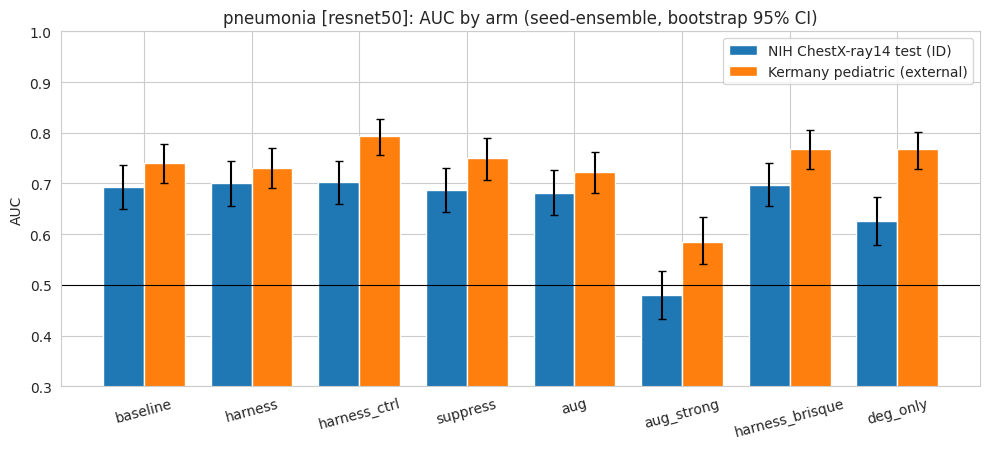

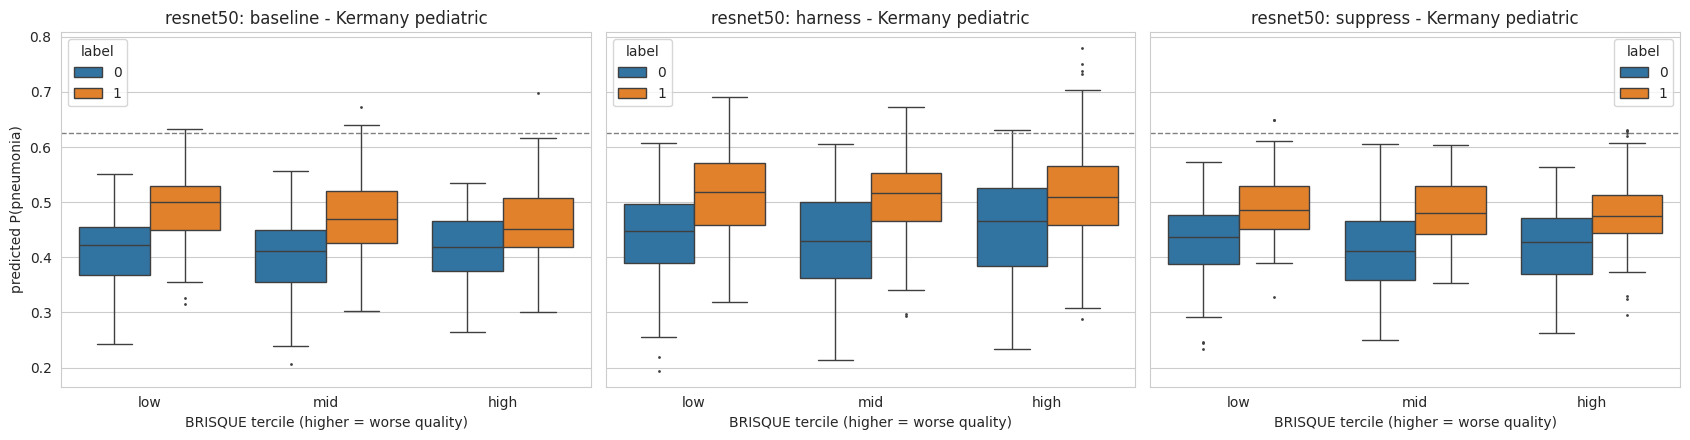

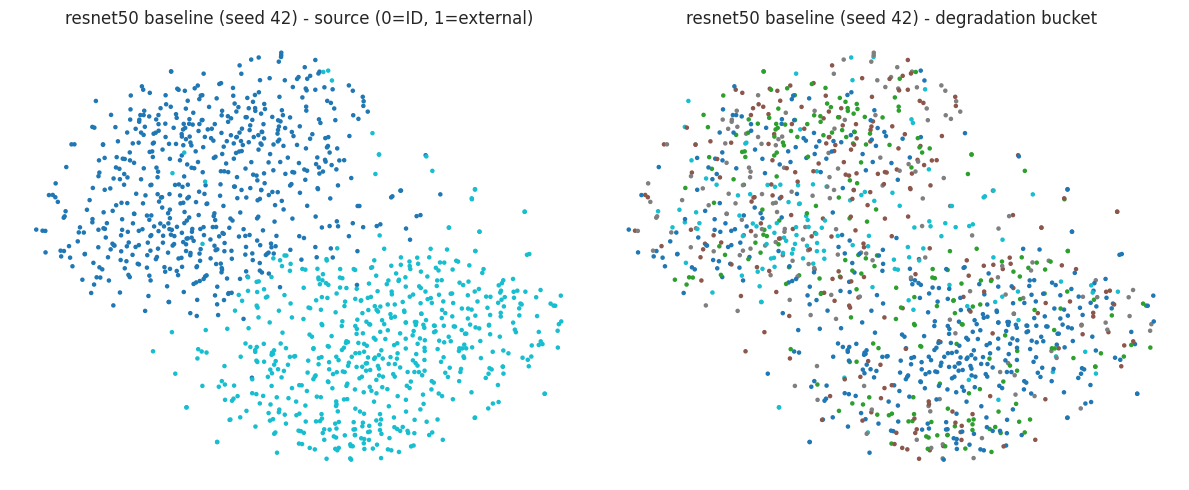

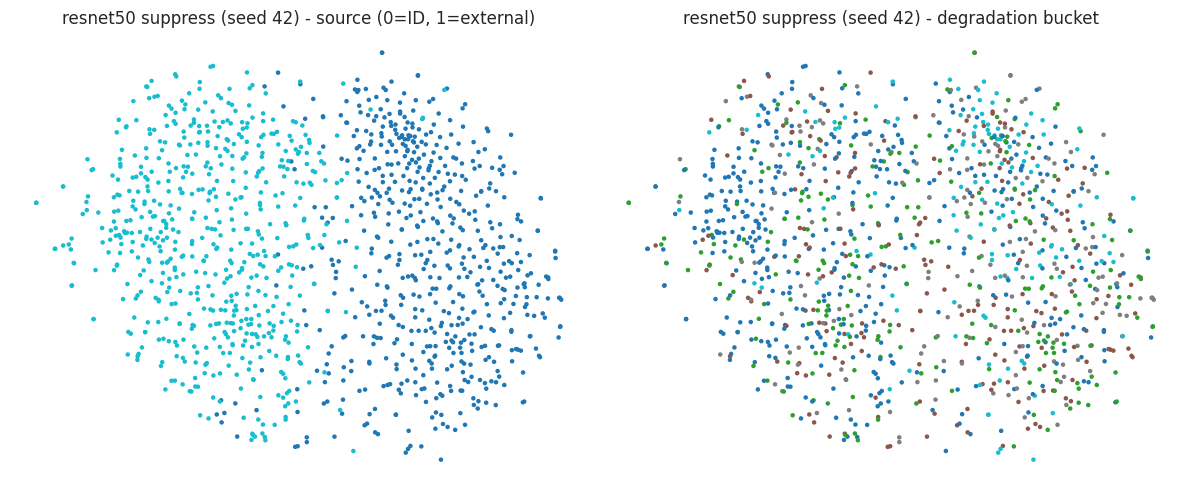

[backbone] convnext_tiny: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING convnext_tiny ==============================
[convnext_tiny] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [convnext_tiny] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.746     0.662
    baseline     7    0.737     0.793
    baseline  2024    0.728     0.811
    baseline    11    0.737     0.876
    baseline    99    0.708     0.895
     harness    42    0.710     0.823
     harness     7    0.729     0.883
     harness  2024    0.740     0.781
     harness    11    0.733     0.714
     harness    99    0.749     0.660
harness_ctrl    42    0.719     0.837
harness_ctrl     7    0.730     0.896
harness_ctrl  2024    0.733     0.781
harness_ctrl    11    0.725     0.816
harness_ctrl    99    0.752     0.656
    suppress    42    0.723     0.822
    suppress     7    0.729     0.740
    suppress  2

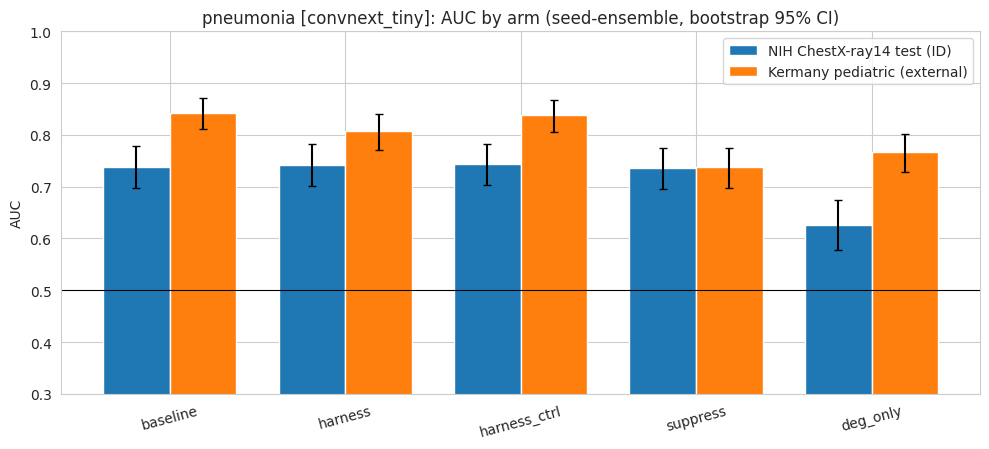

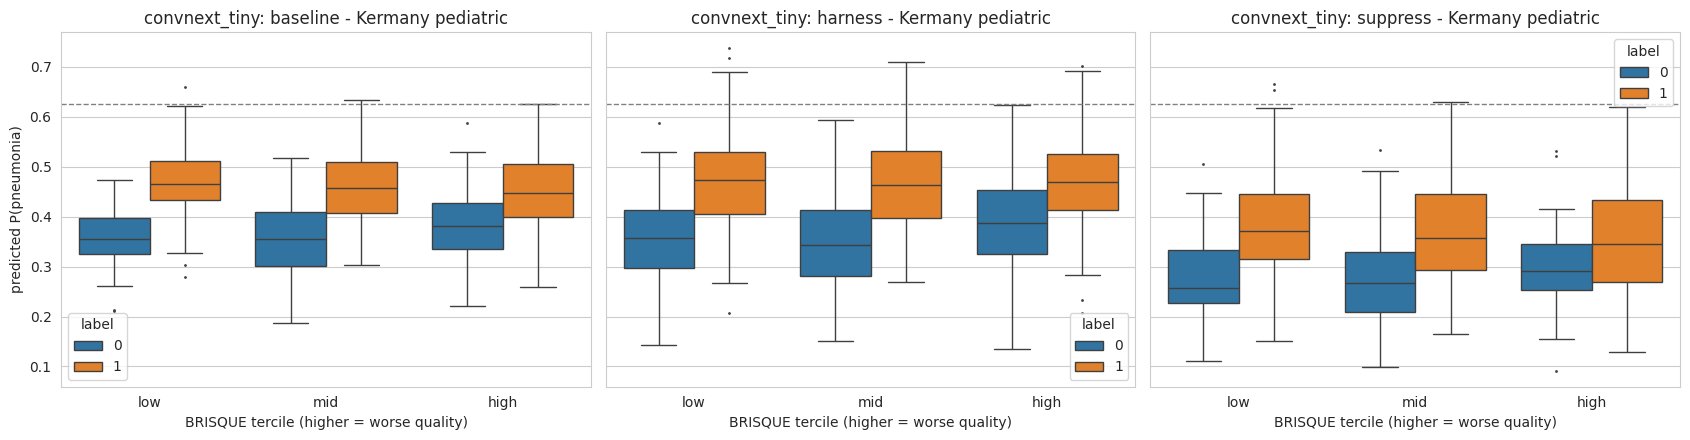

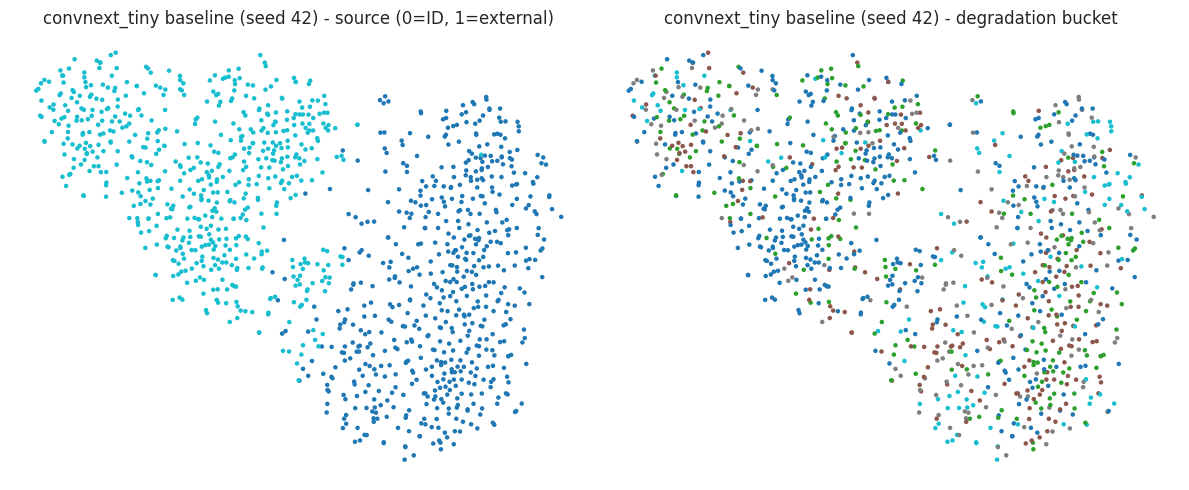

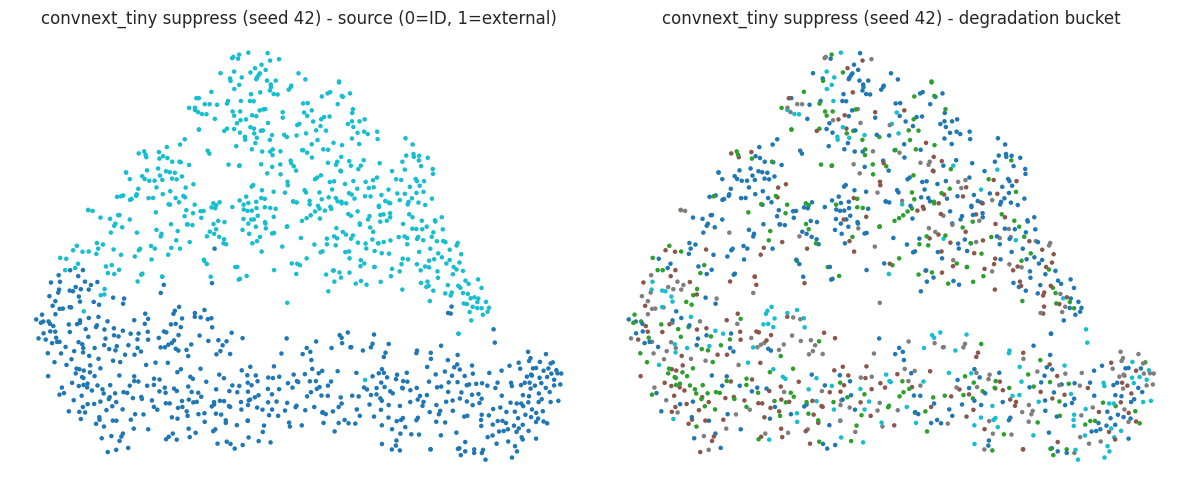

[backbone] vit_small_patch16_224: feat_dim=384 mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)

============================== EVALUATING vit_small_patch16_224 ==============================
[vit_small_patch16_224] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [vit_small_patch16_224] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.710     0.725
    baseline     7    0.712     0.798
    baseline  2024    0.724     0.683
    baseline    11    0.737     0.794
    baseline    99    0.721     0.786
     harness    42    0.727     0.775
     harness     7    0.741     0.833
     harness  2024    0.723     0.713
     harness    11    0.718     0.813
     harness    99    0.728     0.732
harness_ctrl    42    0.730     0.793
harness_ctrl     7    0.736     0.722
harness_ctrl  2024    0.715     0.714
harness_ctrl    11    0.716     0.830
harness_ctrl    99    0.730     0.746
    suppress    42    0.730     0.734
    suppress     7    0.729     0

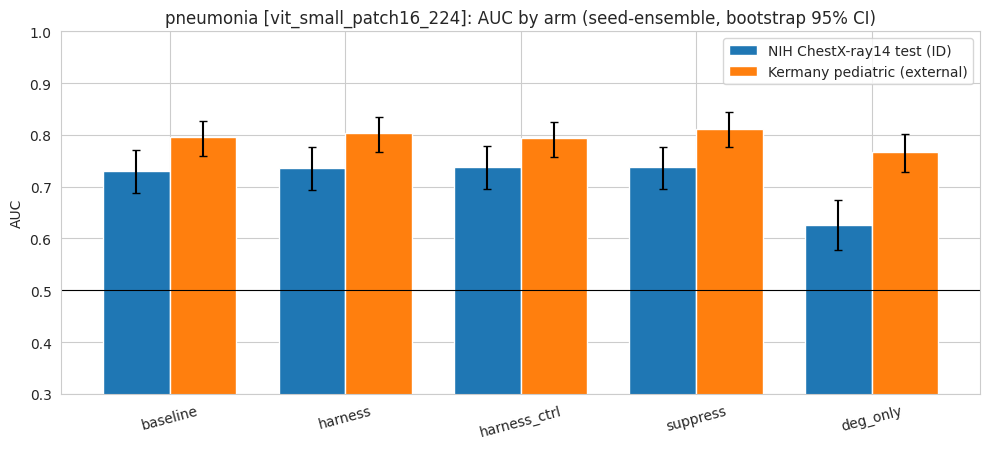

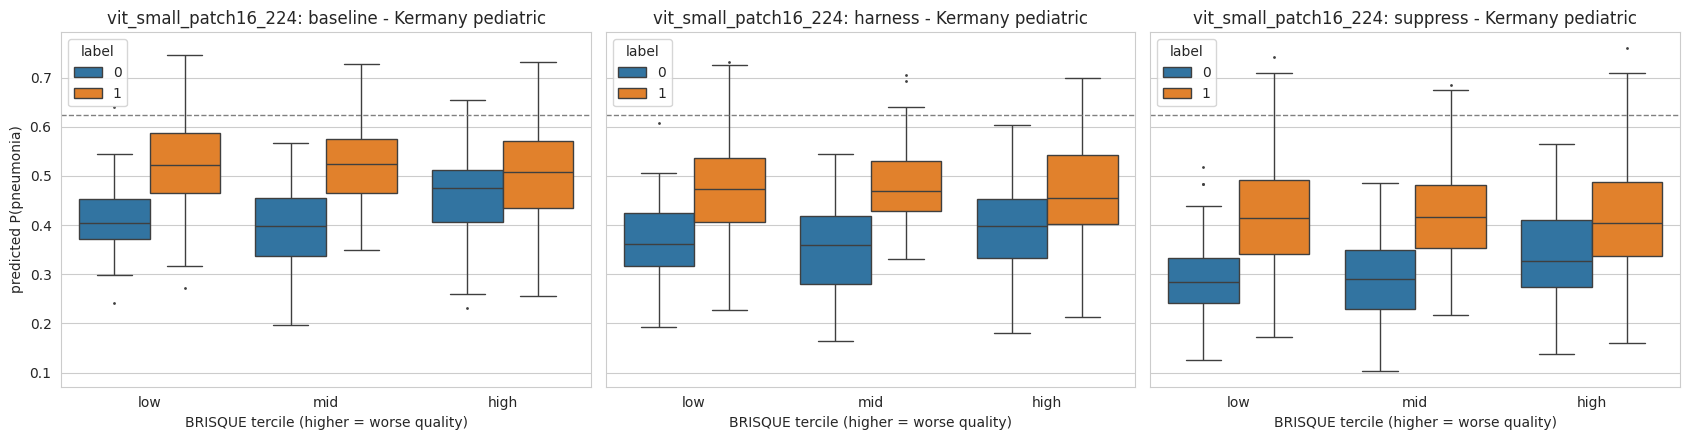

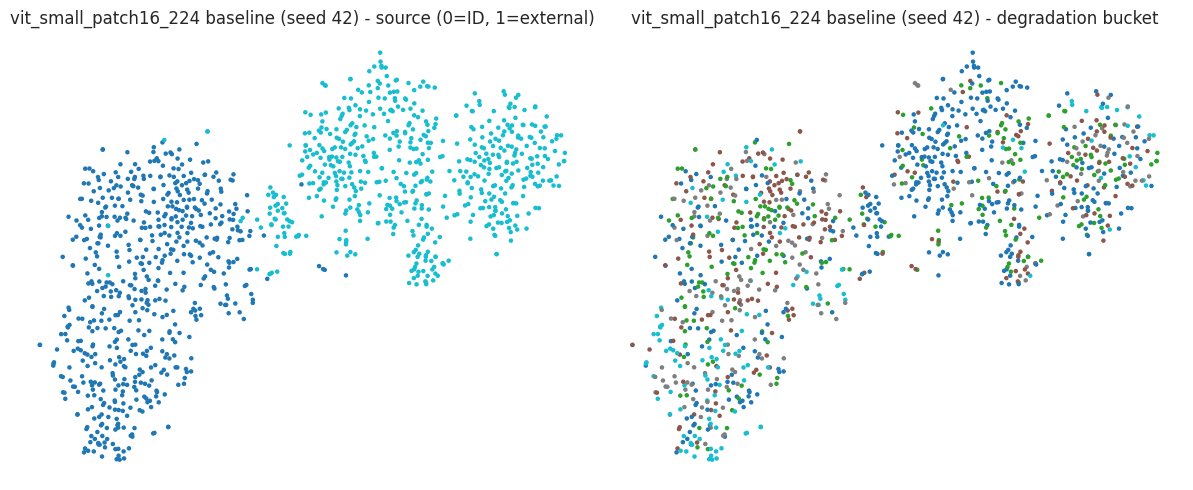

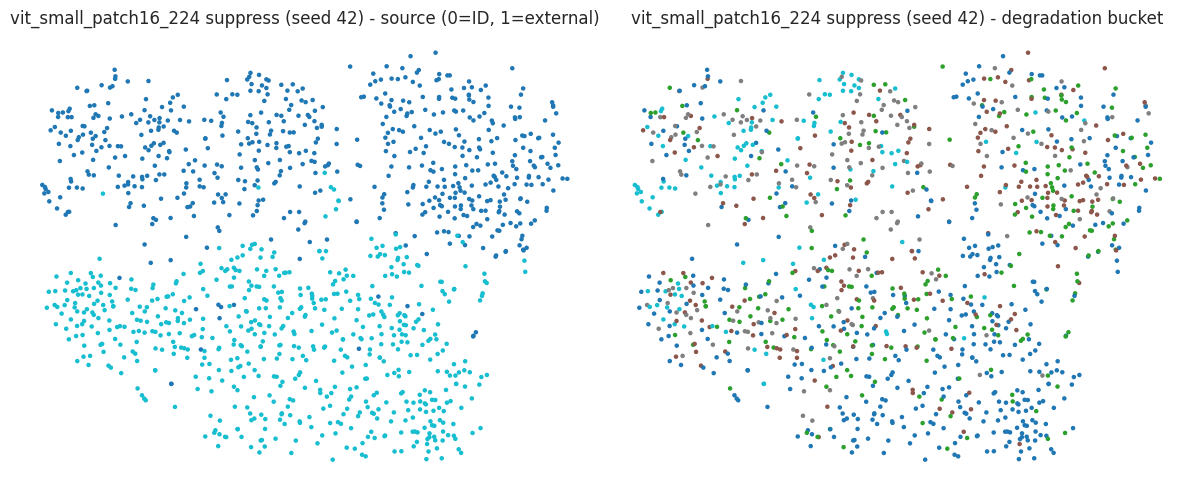

[backbone] densenet121: feat_dim=1024 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING densenet121 ==============================
[densenet121] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [densenet121] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.709     0.628
    baseline     7    0.716     0.700
    baseline  2024    0.708     0.470
    baseline    11    0.696     0.691
    baseline    99    0.727     0.681
     harness    42    0.690     0.629
     harness     7    0.708     0.601
     harness  2024    0.696     0.558
     harness    11    0.694     0.579
     harness    99    0.677     0.595
harness_ctrl    42    0.721     0.713
harness_ctrl     7    0.726     0.619
harness_ctrl  2024    0.690     0.576
harness_ctrl    11    0.702     0.585
harness_ctrl    99    0.688     0.507
    suppress    42    0.678     0.633
    suppress     7    0.701     0.637
    suppress  2024    

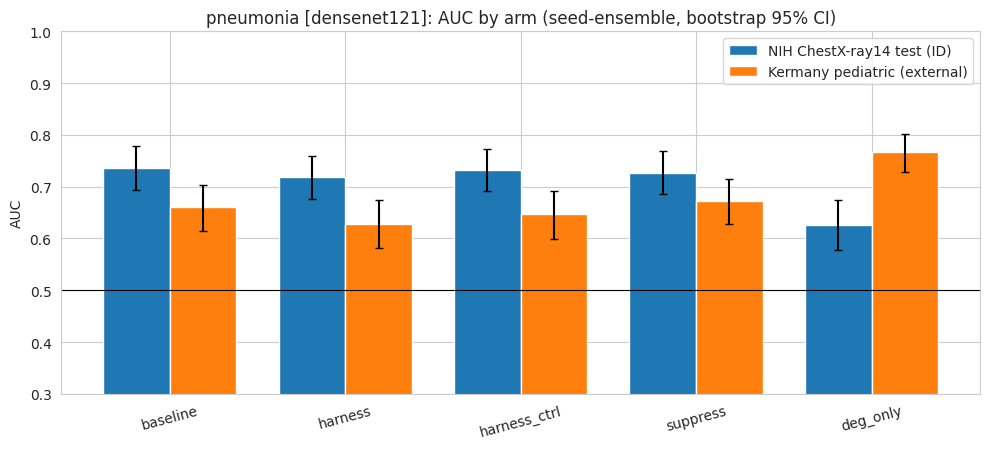

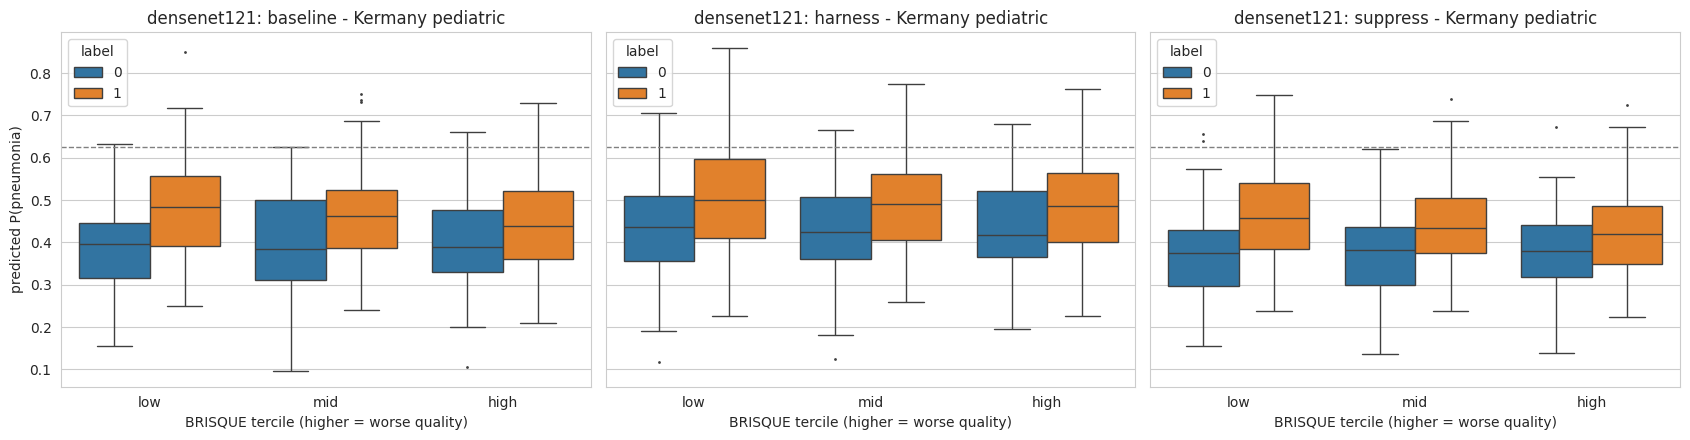

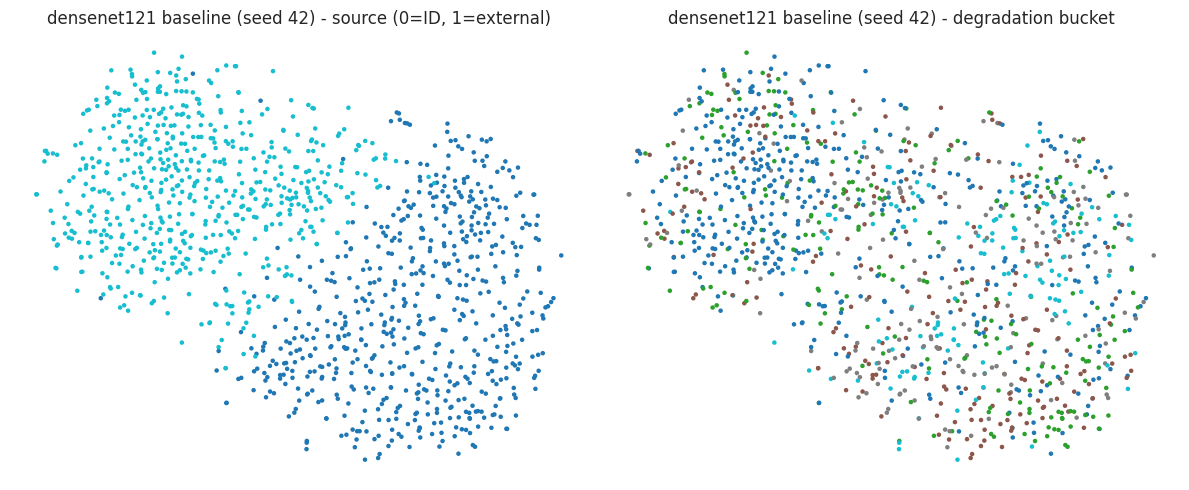

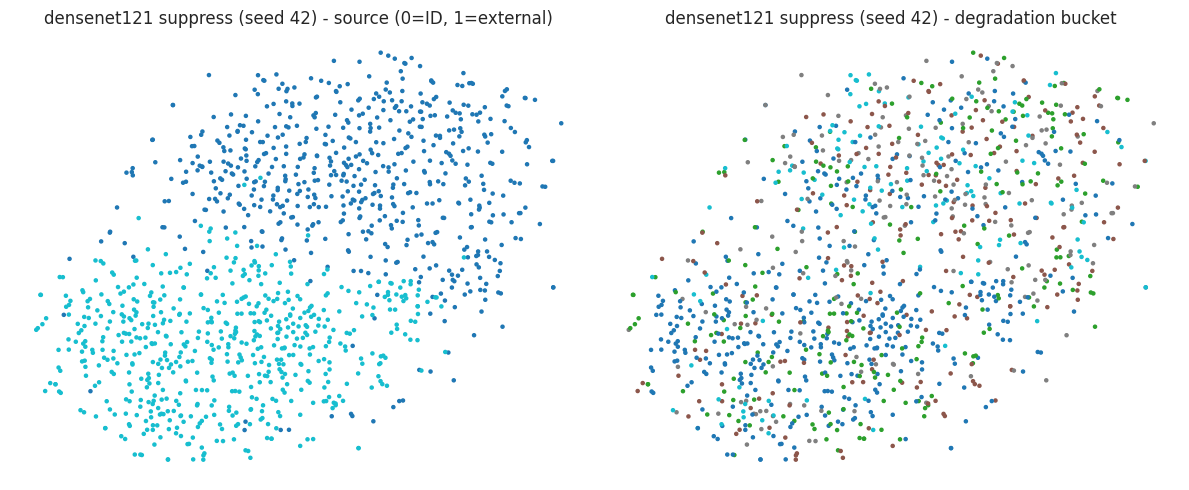

[backbone] efficientnet_b0: feat_dim=1280 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING efficientnet_b0 ==============================
[efficientnet_b0] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [efficientnet_b0] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.700     0.738
    baseline     7    0.706     0.685
    baseline  2024    0.707     0.485
    baseline    11    0.719     0.613
    baseline    99    0.687     0.752
     harness    42    0.730     0.792
     harness     7    0.707     0.609
     harness  2024    0.718     0.640
     harness    11    0.719     0.694
     harness    99    0.714     0.566
harness_ctrl    42    0.733     0.791
harness_ctrl     7    0.706     0.612
harness_ctrl  2024    0.730     0.717
harness_ctrl    11    0.717     0.741
harness_ctrl    99    0.715     0.613
    suppress    42    0.724     0.725
    suppress     7    0.726     0.777
    su

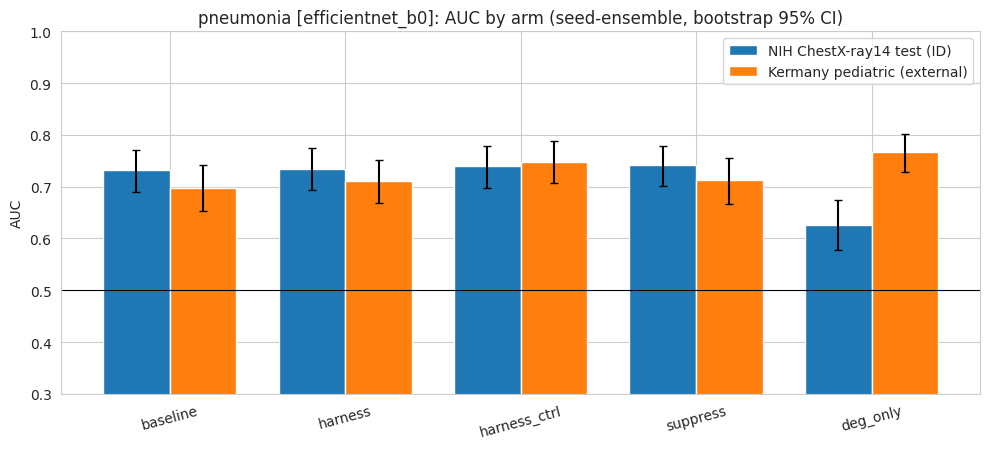

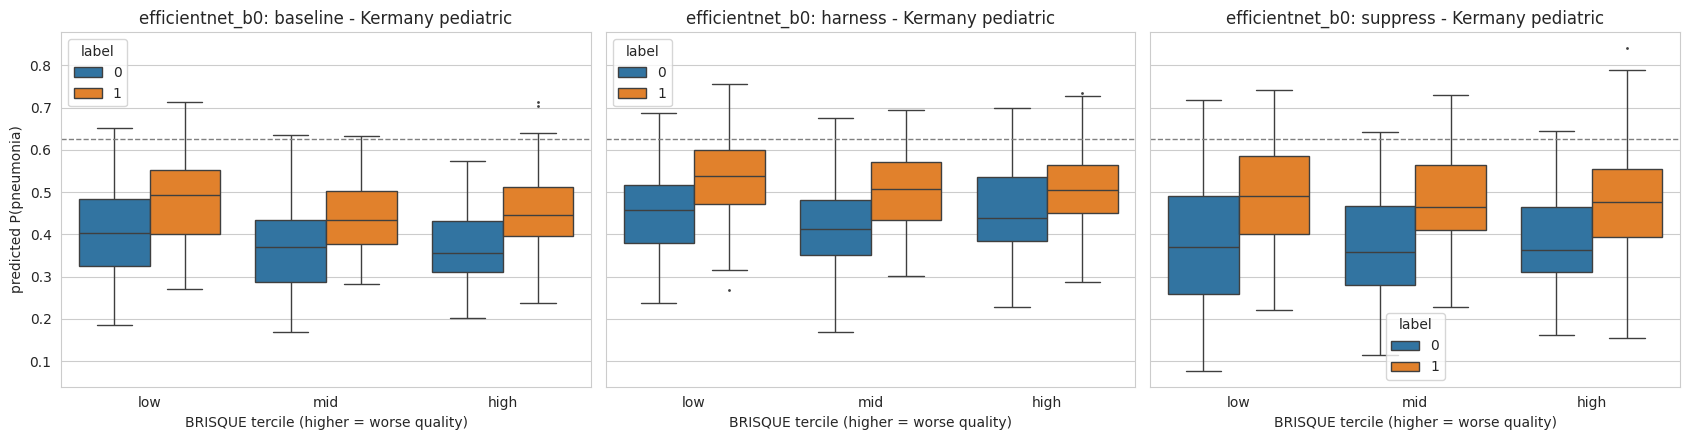

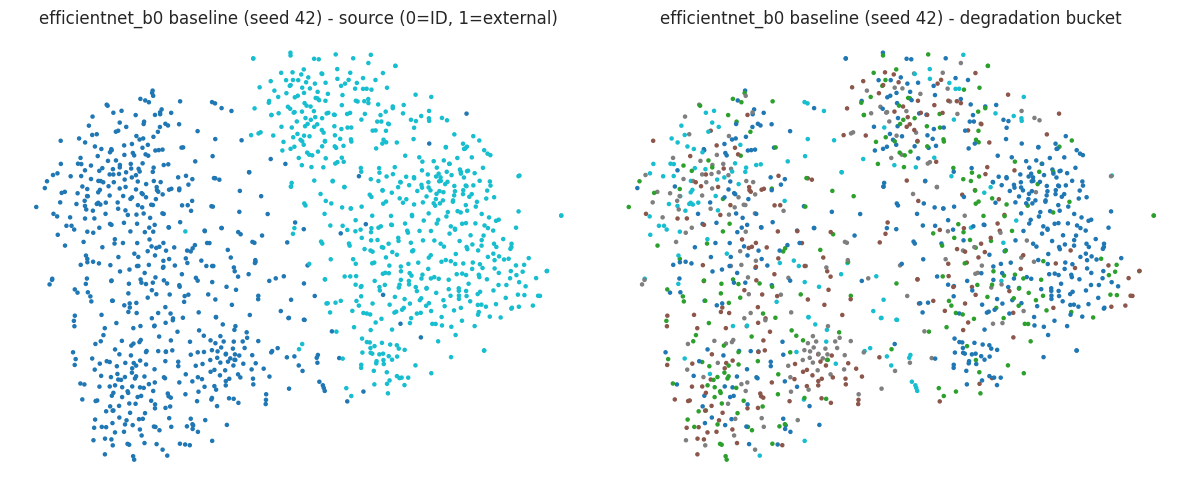

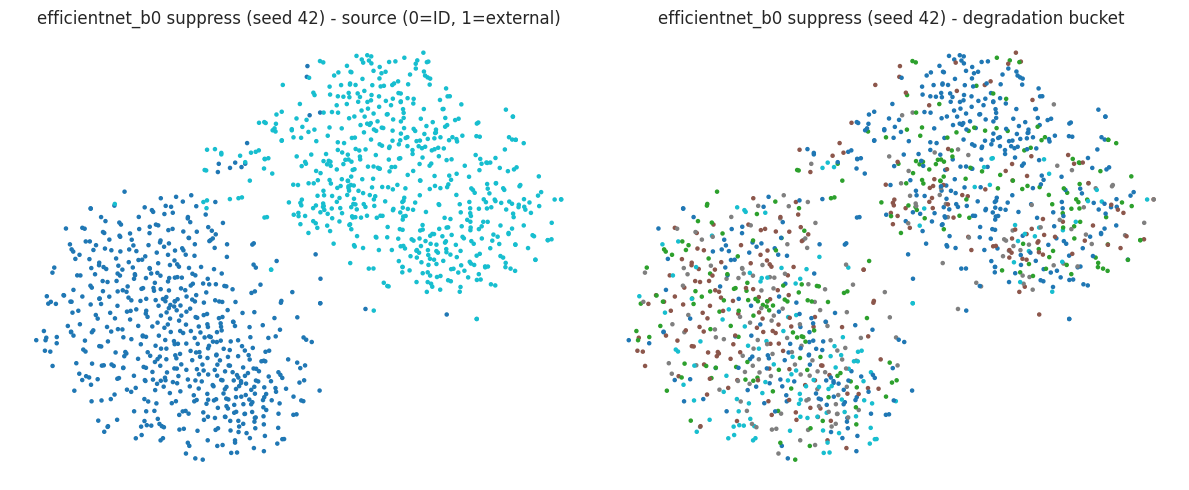

[backbone] swin_tiny_patch4_window7_224: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING swin_tiny_patch4_window7_224 ==============================
[swin_tiny_patch4_window7_224] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [swin_tiny_patch4_window7_224] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.750     0.865
    baseline     7    0.755     0.622
    baseline  2024    0.737     0.775
    baseline    11    0.732     0.731
    baseline    99    0.757     0.841
     harness    42    0.743     0.786
     harness     7    0.741     0.787
     harness  2024    0.750     0.688
     harness    11    0.748     0.760
     harness    99    0.749     0.791
harness_ctrl    42    0.745     0.753
harness_ctrl     7    0.740     0.712
harness_ctrl  2024    0.753     0.844
harness_ctrl    11    0.751     0.794
harness_ctrl    99    0.749     0.848
    suppress    42    0.767    

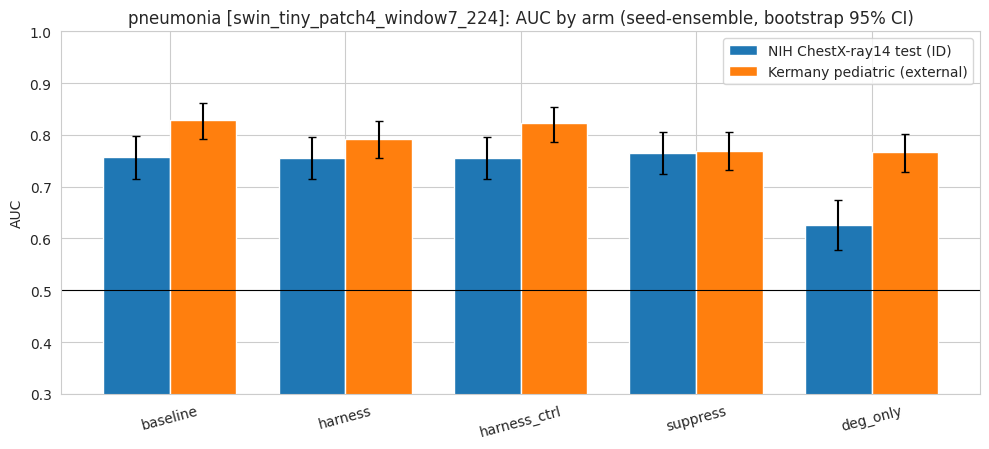

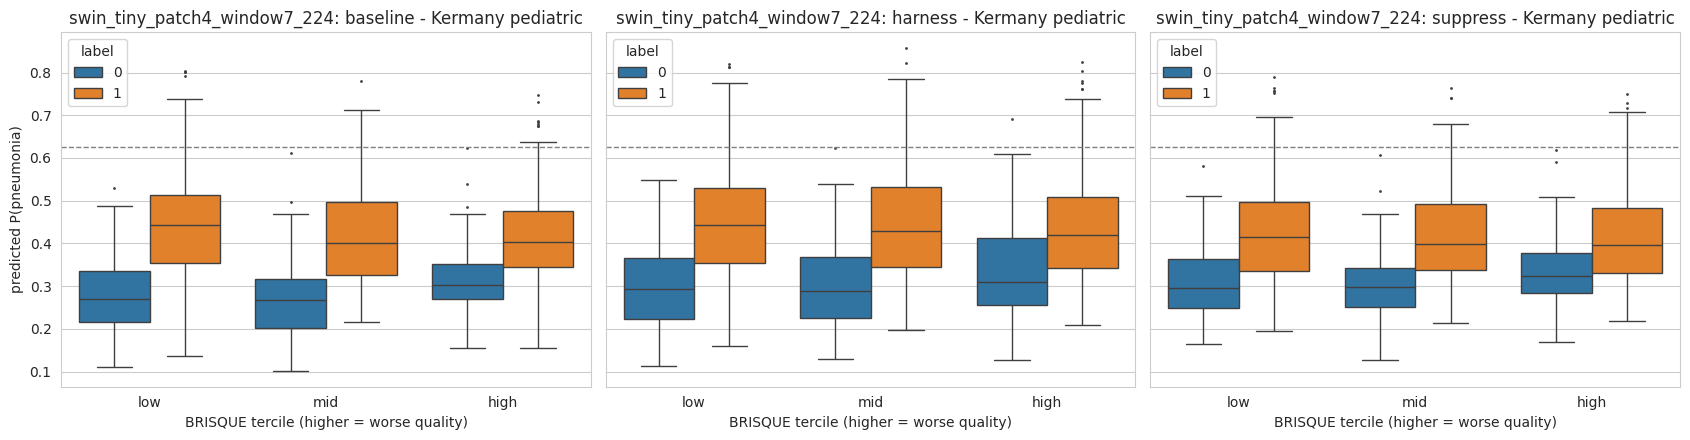

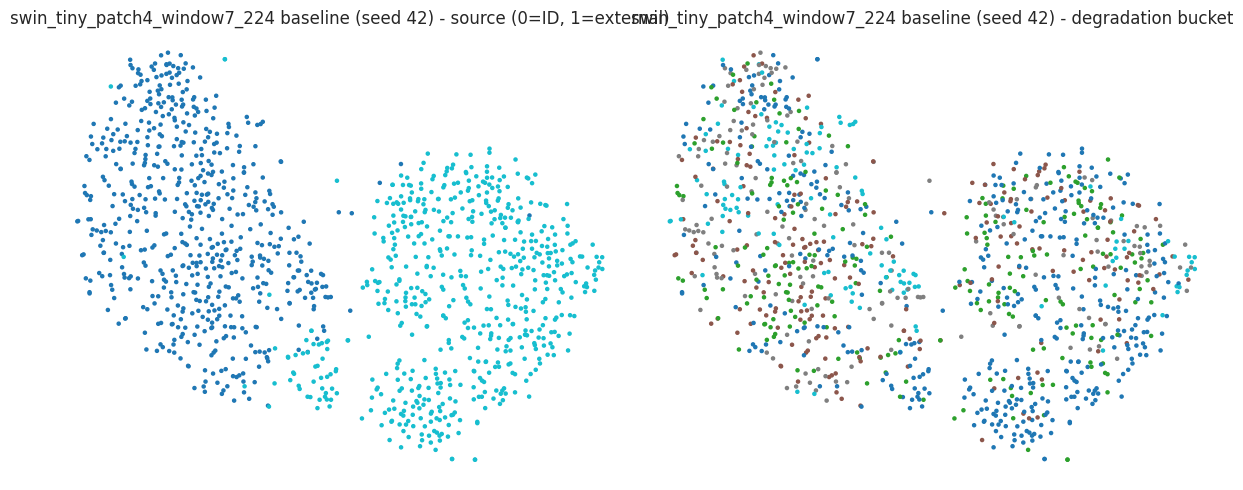

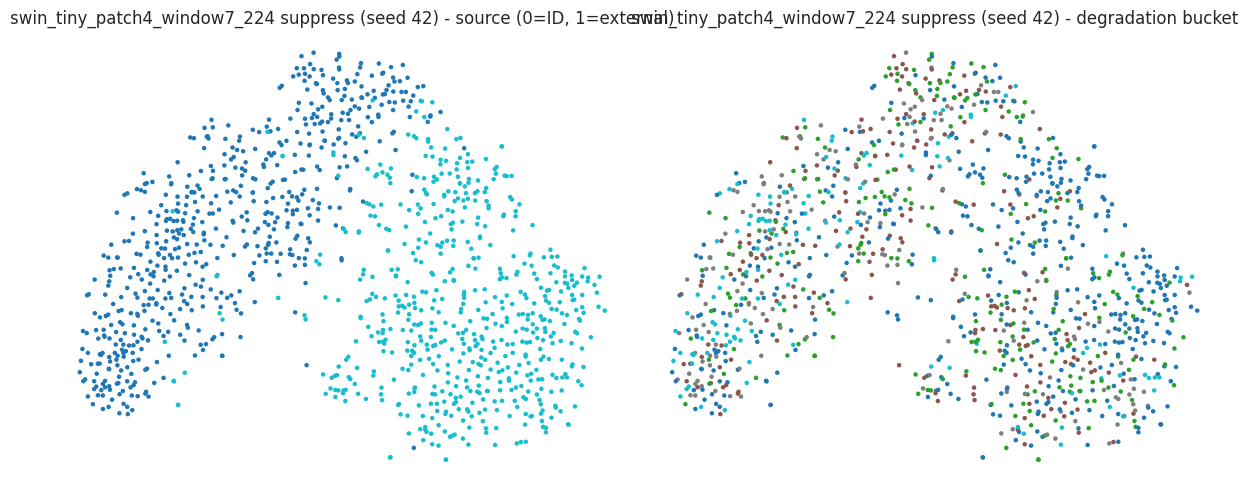

In [9]:
# One loop over the backbones. For each: reload every saved full model, evaluate, write tables/figures tagged <TAG>_<backbone>.
# (Variables below are deliberately left in the notebook namespace after the loop, so the last backbone can be inspected.)
BBS_DONE = []
for BB_ in BACKBONES:
    set_backbone(BB_); ARMS = ARMS_FOR[BB_]; TAGB = f'{TAG}_{BB_}'
    print('\n' + '=' * 30, 'EVALUATING', BB_, '=' * 30)
    # =========================== 6a. inference with the FULL saved model (backbone + all heads) ===========================
    SEEDS_OK = [s for s in SEEDS if all(ckpt_valid(ckpt_path(m, s)) is not None for m in ARMS)]
    if not SEEDS_OK:
        print(f'[{BB}] no seed has valid checkpoints for ALL arms (time budget / other session) - skipped here.'); continue
    if len(SEEDS_OK) < 3:
        print(f'[{BB}] WARNING: only {len(SEEDS_OK)} complete seed(s): {SEEDS_OK} - report this honestly in the paper.')
    PROBE_SEEDS = SEEDS_OK[:PROBE_SEEDS_N]
    va_feat = FD[FD.source == SRC_VA].reset_index(drop=True)
    te_feat = FD[FD.source == SRC_TE].reset_index(drop=True)
    ex_feat = FD[FD.source == SRC_EX].reset_index(drop=True)
    Y = {'va': va_feat.label.values.astype(int), 'te': te_feat.label.values.astype(int), 'ex': ex_feat.label.values.astype(int)}
    SPLIT_NAME = {'te': f'{NAME_ID} test (ID)', 'ex': f'{NAME_EX} (external)'}

    @torch.no_grad()
    def run_ckpt(mode, seed, dfs, want_feats=(), deg_mode=None):
        """deg_mode (test-time intervention, harness-type arms only): None = real degradation vector; 'zero' = train-mean fill (z-score 0);
        'shuffle' = vectors permuted across the images of the evaluated set (breaks the image<->degradation link)."""
        c = ckpt_valid(ckpt_path(mode, seed))
        bb, fwd, extra, ph = make_model(mode, pretrained=False)
        bb.load_state_dict(c['bb'])
        assert len(extra) == len(c['extra']), 'head count mismatch between model and checkpoint'
        for m, sd in zip(extra, c['extra']):
            m.load_state_dict(sd)                                   # every saved head state IS consumed
        bb.eval(); [m.eval() for m in extra]
        out = {}
        for k, df in dfs.items():
            perm = np.random.default_rng(seed + 1).permutation(len(df)) if mode == 'harness_ctrl' else None
            ds_ = DS(df, eval_tf, perm)
            if deg_mode == 'zero': ds_.deg = torch.zeros_like(ds_.deg)
            elif deg_mode == 'shuffle': ds_.deg = ds_.deg[torch.from_numpy(np.random.default_rng(123).permutation(len(ds_)))]
            ld = _loader(ds_, 64, False, persistent=False)
            ps, fs = [], []
            for img, y, deg, bkt in ld:
                with torch.autocast(device_type='cuda', enabled=AMP):
                    logits, f = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu())
                if k in want_feats: fs.append(f.float().cpu())
            out[k] = (torch.cat(ps).numpy(), torch.cat(fs).numpy() if fs else None)
        del bb, fwd, extra, ph; torch.cuda.empty_cache()
        return out, c['val_auc']

    P = {m: {} for m in ARMS}          # P[arm][seed] = {'va','te','ex'} probabilities
    FEATS_PS = {m: {} for m in ARMS}   # penultimate features (probe seeds only)
    sanity = []
    for seed in SEEDS_OK:
        for mode in ARMS:
            want = ('va', 'te', 'ex') if seed in PROBE_SEEDS else ()
            out, logged = run_ckpt(mode, seed, {'va': va_feat, 'te': te_feat, 'ex': ex_feat}, want)
            P[mode][seed] = {k: out[k][0] for k in ('va', 'te', 'ex')}
            if want: FEATS_PS[mode][seed] = {k: out[k][1] for k in ('va', 'te', 'ex')}
            re_auc = roc_auc_score(Y['va'], P[mode][seed]['va'])
            sanity.append({'arm': mode, 'seed': seed, 'val_auc_logged': logged, 'val_auc_reloaded': re_auc})
            # DATA-AGNOSTIC SANITY GUARD: the reloaded model must reproduce the validation AUC logged during training
            if abs(re_auc - logged) > 0.02:
                raise RuntimeError(f'CHECKPOINT ROUND-TRIP FAILED for {mode}/s{seed}: logged {logged:.3f} vs reloaded {re_auc:.3f} '
                                   '(heads not loaded / wrong feature path). Do NOT use any number below.')
    sanity = pd.DataFrame(sanity); sanity.to_csv(f'{RES}/sanity_roundtrip_{TAGB}.csv', index=False)
    print(f'[{BB}] checkpoint round-trip OK; max |logged - reloaded| val AUC = %.4f' % (sanity.val_auc_logged - sanity.val_auc_reloaded).abs().max())

    # ensemble = mean of PROBABILITIES over seeds (not mean of AUCs)
    PE = {m: {k: np.mean([P[m][s][k] for s in SEEDS_OK], axis=0) for k in ('va', 'te', 'ex')} for m in ARMS}
    PE['deg_only'] = dict(DEG_SCORE)                      # degradation-features-only logistic regression (no image)
    ALL_ROWS = ARMS + ['deg_only']
    sa = pd.DataFrame([{'arm': m, 'seed': s, 'id_test': roc_auc_score(Y['te'], P[m][s]['te']), 'external': roc_auc_score(Y['ex'], P[m][s]['ex'])}
                       for m in ARMS for s in SEEDS_OK])
    print(f'--- [{BB}] per-seed AUCs ---'); print(sa.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    sa.to_csv(f'{RES}/table2_seeds_{TAGB}.csv', index=False)

    # =========================== 6b. paper tables ===========================
    def boot_auc(y, p, n=2000, seed=1):
        rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); a = []
        for _ in range(n):
            idx = rng.integers(0, len(y), len(y))
            if y[idx].min() == y[idx].max(): continue
            a.append(roc_auc_score(y[idx], p[idx]))
        return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

    def paired_delta_auc(y, p1, p2, n=2000, seed=1):
        """Bootstrap of AUC(p1)-AUC(p2) on the SAME resampled indices."""
        rng = np.random.default_rng(seed); y = np.asarray(y); p1 = np.asarray(p1); p2 = np.asarray(p2); d = []
        for _ in range(n):
            idx = rng.integers(0, len(y), len(y))
            if y[idx].min() == y[idx].max(): continue
            d.append(roc_auc_score(y[idx], p1[idx]) - roc_auc_score(y[idx], p2[idx]))
        d = np.asarray(d); lo, hi = np.percentile(d, [2.5, 97.5])
        p = max(2.0 * min((d <= 0).mean(), (d >= 0).mean()), 1.0 / (len(d) + 1))
        return float(d.mean()), float(lo), float(hi), float(min(1.0, p))

    def holm(pvals):
        p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
        for rank, i in enumerate(order):
            run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
        return adj

    def ece(y, p, n_bins=10):
        y = np.asarray(y); p = np.asarray(p); edges = np.linspace(0, 1, n_bins + 1); e = 0.0
        for i in range(n_bins):
            m = (p > edges[i]) & (p <= edges[i + 1]) if i else (p <= edges[i + 1])
            if m.sum(): e += m.mean() * abs(y[m].mean() - p[m].mean())
        return float(e)

    def youden_threshold(y, p):
        ts = np.unique(p); best, bt = -1, 0.5
        for t in ts[:: max(1, len(ts) // 400)]:
            sens = ((p >= t) & (y == 1)).sum() / max(1, (y == 1).sum()); spec = ((p < t) & (y == 0)).sum() / max(1, (y == 0).sum())
            if sens + spec - 1 > best: best, bt = sens + spec - 1, t
        return float(bt)

    # ---- Table 2: main results (ensemble AUC + CI, per-seed mean+-std, AUPRC, ECE, sens/spec at the ID-val Youden threshold) ----
    rows = []
    for m in ALL_ROWS:
        thr = youden_threshold(Y['va'], PE[m]['va'])
        for k in ('te', 'ex'):
            y, p = Y[k], PE[m][k]; lo, hi = boot_auc(y, p)
            r = {'arm': m, 'eval': k, 'AUC_ens': roc_auc_score(y, p), 'CI_lo': lo, 'CI_hi': hi,
                 'AUPRC': average_precision_score(y, p), 'prevalence': y.mean(),
                 'sens@IDthr': ((p >= thr) & (y == 1)).sum() / max(1, (y == 1).sum()),
                 'spec@IDthr': ((p < thr) & (y == 0)).sum() / max(1, (y == 0).sum()), 'n': len(y)}
            t90 = np.quantile(p[y == 0], 0.90); t95 = np.quantile(p[y == 0], 0.95)          # per-set operating points (optimistic: threshold tuned on the evaluated set)
            r['sens@spec90'] = float((p[y == 1] > t90).mean()); r['sens@spec95'] = float((p[y == 1] > t95).mean())
            if m in ARMS:
                col = 'id_test' if k == 'te' else 'external'
                r.update({'AUC_seed_mean': sa[sa.arm == m][col].mean(), 'AUC_seed_std': sa[sa.arm == m][col].std(), 'ECE': ece(y, p)})
            rows.append(r)
    res = pd.DataFrame(rows)
    print(f'--- [{BB}] Table 2: main results ---'); print(res.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    res.to_csv(f'{RES}/table2_main_{TAGB}.csv', index=False)

    # ---- Table 2b: paired bootstrap dAUC (ensemble) + per-seed consistency + Holm correction ----
    COMPS = [c for c in [('harness', 'baseline'), ('harness', 'harness_ctrl'), ('suppress', 'baseline'), ('aug', 'baseline'),
                         ('suppress', 'harness'), ('aug', 'suppress'), ('aug_strong', 'baseline'), ('harness_brisque', 'baseline'),
                         ('harness', 'harness_brisque'), ('harness', 'aug')] if c[0] in ARMS and c[1] in ARMS]
    dl = []
    for k in ('te', 'ex'):
        for a, b in COMPS:
            m_, lo, hi, pv = paired_delta_auc(Y[k], PE[a][k], PE[b][k])
            per_seed = np.array([roc_auc_score(Y[k], P[a][s][k]) - roc_auc_score(Y[k], P[b][s][k]) for s in SEEDS_OK])
            dl.append({'eval': {'te': 'id_test', 'ex': 'external'}[k], 'comparison': f'{a} - {b}', 'dAUC': m_, 'CI_lo': lo, 'CI_hi': hi,
                       'p_value': pv, 'seed_dAUC_mean': per_seed.mean(), 'seed_dAUC_std': per_seed.std(ddof=1) if len(per_seed) > 1 else np.nan,
                       'seeds_same_sign': int((np.sign(per_seed) == np.sign(per_seed.mean())).sum()), 'n_seeds': len(per_seed)})
    delt = pd.DataFrame(dl)
    delt['p_holm'] = np.nan
    for ev in delt['eval'].unique():
        ix = delt.index[delt['eval'] == ev]; delt.loc[ix, 'p_holm'] = holm(delt.loc[ix, 'p_value'].values)
    print(f'--- [{BB}] Table 2b: paired dAUC ---'); print(delt.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    delt.to_csv(f'{RES}/table2b_deltas_{TAGB}.csv', index=False)

    # ---- Table 3: AUC within BRISQUE terciles (within each evaluation set) + stratum-averaged AUC ----
    tr_rows = []
    for k, dfk in (('te', te_feat), ('ex', ex_feat)):
        terc = pd.qcut(dfk['brisque'], 3, labels=['low', 'mid', 'high']).astype(str).values
        for m in ALL_ROWS:
            aucs, ns = [], []
            for t in ['low', 'mid', 'high']:
                ix = terc == t; yy = Y[k][ix]
                if ix.sum() > 10 and 0 < yy.sum() < ix.sum():
                    a = roc_auc_score(yy, PE[m][k][ix]); aucs.append(a); ns.append(ix.sum())
                    tr_rows.append({'eval': k, 'arm': m, 'tercile': t, 'AUC': a, 'n': int(ix.sum()), 'n_pos': int(yy.sum())})
            if aucs:
                tr_rows.append({'eval': k, 'arm': m, 'tercile': 'STRATUM-MEAN', 'AUC': float(np.average(aucs, weights=ns)), 'n': int(sum(ns)), 'n_pos': -1})
    terc_df = pd.DataFrame(tr_rows)
    print(f'--- [{BB}] Table 3: AUC within degradation terciles ---')
    print(terc_df.pivot_table(index=['eval', 'arm'], columns='tercile', values='AUC').round(3).to_string())
    terc_df.to_csv(f'{RES}/table3_terciles_{TAGB}.csv', index=False)

    # ---- Table 7: shortcut reliance = rank correlation of each arm's score with the degradation-only score / raw BRISQUE ----
    sc = []
    for k, dfk in (('te', te_feat), ('ex', ex_feat)):
        for m in ARMS:
            sc.append({'eval': k, 'arm': m, 'spearman_vs_deg_only_score': spearmanr(PE[m][k], PE['deg_only'][k])[0],
                       'spearman_vs_BRISQUE': spearmanr(PE[m][k], dfk['brisque'].values)[0]})
    sc = pd.DataFrame(sc); print(f'--- [{BB}] Table 7: score <-> degradation correlation ---'); print(sc.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    sc.to_csv(f'{RES}/table7_score_degradation_corr_{TAGB}.csv', index=False)

    # ---- Table 8: does the arm's benefit TRANSFER?  gap = dAUC(external) - dAUC(ID); independent bootstrap over the two test sets ----
    def transfer_gap(y_id, a_id, b_id, y_ex, a_ex, b_ex, n=2000, seed=3):
        rng = np.random.default_rng(seed); g = []
        for _ in range(n):
            i = rng.integers(0, len(y_id), len(y_id)); j = rng.integers(0, len(y_ex), len(y_ex))
            if y_id[i].min() == y_id[i].max() or y_ex[j].min() == y_ex[j].max(): continue
            g.append((roc_auc_score(y_ex[j], a_ex[j]) - roc_auc_score(y_ex[j], b_ex[j])) - (roc_auc_score(y_id[i], a_id[i]) - roc_auc_score(y_id[i], b_id[i])))
        g = np.asarray(g); lo, hi = np.percentile(g, [2.5, 97.5])
        return float(g.mean()), float(lo), float(hi), float(min(1.0, max(2 * min((g <= 0).mean(), (g >= 0).mean()), 1 / (len(g) + 1))))
    tg = []
    for a, b in [c for c in [('harness', 'baseline'), ('suppress', 'baseline'), ('aug', 'baseline'), ('harness', 'harness_ctrl'), ('aug_strong', 'baseline'), ('harness_brisque', 'baseline')] if c[0] in ARMS and c[1] in ARMS]:
        m_, lo, hi, pv = transfer_gap(Y['te'], PE[a]['te'], PE[b]['te'], Y['ex'], PE[a]['ex'], PE[b]['ex'])
        tg.append({'comparison': f'{a} - {b}', 'gap_ext_minus_id': m_, 'CI_lo': lo, 'CI_hi': hi, 'p_value': pv})
    tg = pd.DataFrame(tg); tg['p_holm'] = holm(tg.p_value.values)
    print(f'--- [{BB}] Table 8: transfer gap of each arm benefit (negative = benefit does NOT transfer) ---')
    print(tg.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    tg.to_csv(f'{RES}/table8_transfer_gap_{TAGB}.csv', index=False)


    # ---- Table 13: TEST-TIME INTERVENTION on the degradation input of harness-type models (causal use of the degradation vector) ----
    # same trained weights, only the degradation vector fed at inference changes: real / zero (train mean) / shuffled across images.
    # If the harness benefit is really *used* information, AUC(real) > AUC(zero) ~ AUC(shuffle); if AUC(zero) ~ AUC(real), the vector is ignored
    # and any ID/OOD difference vs baseline is just a different optimisation path.
    iv_rows = []; INTV = {}      # INTV[(arm, dm)][seed][k] = probabilities with the degradation vector intervened on
    for mode in [m for m in ('harness', 'harness_brisque') if m in ARMS]:
        PI = {dm: {} for dm in ('real', 'zero', 'shuffle')}
        for seed in SEEDS_OK:
            for dm in ('zero', 'shuffle'):
                out, _ = run_ckpt(mode, seed, {'te': te_feat, 'ex': ex_feat}, deg_mode=dm)
                PI[dm][seed] = {k: out[k][0] for k in ('te', 'ex')}
            PI['real'][seed] = {k: P[mode][seed][k] for k in ('te', 'ex')}
        if mode == 'harness': INTV = {('harness', dm): PI[dm] for dm in ('zero', 'shuffle')}
        for k in ('te', 'ex'):
            ens = {dm: np.mean([PI[dm][s][k] for s in SEEDS_OK], axis=0) for dm in PI}
            for dm in ('zero', 'shuffle'):
                d_, lo_, hi_, p_ = paired_delta_auc(Y[k], ens['real'], ens[dm])
                ps_ = np.array([roc_auc_score(Y[k], PI['real'][s][k]) - roc_auc_score(Y[k], PI[dm][s][k]) for s in SEEDS_OK])
                bl_ = roc_auc_score(Y[k], PE['baseline'][k]) if 'baseline' in PE else np.nan
                iv_rows.append({'arm': mode, 'eval': {'te': 'id_test', 'ex': 'external'}[k], 'intervention': dm,
                                'AUC_real': roc_auc_score(Y[k], ens['real']), 'AUC_intervened': roc_auc_score(Y[k], ens[dm]),
                                'AUC_baseline_arm': bl_, 'drop(real-intervened)': d_, 'CI_lo': lo_, 'CI_hi': hi_, 'p_value': p_,
                                'seeds_drop_positive': f'{int((ps_ > 0).sum())}/{len(ps_)}'})
    iv_df = pd.DataFrame(iv_rows)
    if len(iv_df):
        print(f'--- [{BB}] Table 13: test-time intervention on the degradation vector (drop > 0 => the model USES it) ---')
        print(iv_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
        iv_df.to_csv(f'{RES}/table13_intervention_{TAGB}.csv', index=False)
    # ---- Table 14: the harness model with its degradation channel REMOVED at test time ('harness_zero') as a deployable arm ----
    EXTRA_PRED, EXTRA_SEED = {}, {}
    if INTV:
        t14 = []
        for dm in ('zero', 'shuffle'):
            nm = f'harness_{dm}'
            EXTRA_PRED[nm] = {k: np.mean([INTV[('harness', dm)][s][k] for s in SEEDS_OK], axis=0) for k in ('te', 'ex')}
            for s in SEEDS_OK:
                for k in ('te', 'ex'): EXTRA_SEED[f'ps_{nm}_{s}_{k}'] = INTV[('harness', dm)][s][k]
        for k in ('te', 'ex'):
            for dm in ('zero', 'shuffle'):
                for ref in ('baseline', 'harness'):
                    d_, lo_, hi_, p_ = paired_delta_auc(Y[k], EXTRA_PRED[f'harness_{dm}'][k], PE[ref][k])
                    t14.append({'eval': {'te': 'id_test', 'ex': 'external'}[k], 'comparison': f'harness_{dm} - {ref}', 'AUC_harness_variant': roc_auc_score(Y[k], EXTRA_PRED[f'harness_{dm}'][k]),
                                'dAUC': d_, 'CI_lo': lo_, 'CI_hi': hi_, 'p_value': p_})
        t14 = pd.DataFrame(t14); t14['p_holm'] = holm(t14.p_value.values)
        print(f'--- [{BB}] Table 14: harness model with the degradation vector zeroed / shuffled at test time vs baseline and vs the normal harness ---')
        print(t14.to_string(index=False, float_format=lambda v: f'{v:.4f}')); t14.to_csv(f'{RES}/table14_harness_variants_{TAGB}.csv', index=False)

    np.savez_compressed(f'{RES}/preds_{TAGB}.npz', y_id=Y['te'], y_ex=Y['ex'], y_va=Y['va'], brisque_id=te_feat['brisque'].values,
                        brisque_ex=ex_feat['brisque'].values,
                        **{f'p_{m}_{k}': PE[m][k] for m in ALL_ROWS for k in ('va', 'te', 'ex')},
                        **{f'p_{m}_{k}': EXTRA_PRED[m][k] for m in EXTRA_PRED for k in ('te', 'ex')},
                        **{f'ps_{m}_{s}_{k}': P[m][s][k] for m in ARMS for s in SEEDS_OK for k in ('te', 'ex')},
                        **EXTRA_SEED)
    print('saved ensemble predictions ->', f'preds_{TAGB}.npz')

    # =========================== 6c. forensic probes (held-out, per seed, within-domain) ===========================
    # What changed vs the first version (and why):
    #  * features are NEVER averaged across seeds (coordinates of independently trained networks are not aligned) -> probe each seed, then average;
    #  * degradation decodability is measured WITHIN each domain (otherwise the trivially decodable domain label inflates it);
    #  * quintile buckets are re-computed within each domain -> chance is exactly 0.20 (domain probe chance = 0.50, classes balanced);
    #  * a continuous test is added: held-out R^2 of ridge regression onto the z-scored degradation features (suppress only targets BRISQUE buckets,
    #    so leakage of the OTHER degradation features is the interesting part).
    from sklearn.metrics import r2_score
    BR_IDX = FEATS.index('brisque')
    Xz = {k: X[m] for k, m in (('va', va_mask), ('te', te_mask), ('ex', ex_mask))}      # z-scored degradation features (train statistics)

    def clf_acc(Xm, y, k=5, seed=0):
        skf = StratifiedKFold(k, shuffle=True, random_state=seed)
        pred = cross_val_predict(make_pipeline(VarianceThreshold(1e-8), StandardScaler(), FunctionTransformer(_clip8), LogisticRegression(max_iter=300, C=0.05)), Xm, y, cv=skf)
        return float(accuracy_score(y, pred)), float(balanced_accuracy_score(y, pred))

    def ridge_r2(Xm, Tm, k=5, seed=0):
        pred = cross_val_predict(make_pipeline(VarianceThreshold(1e-8), StandardScaler(), FunctionTransformer(_clip8), RidgeCV(alphas=np.logspace(1, 4, 4))), Xm, Tm,
                                 cv=KFold(k, shuffle=True, random_state=seed))
        return r2_score(Tm, pred, multioutput='raw_values')

    fr_rows = []
    for mode in ARMS:
        for seed in PROBE_SEEDS:
            f = FEATS_PS[mode][seed]
            f_id = np.vstack([f['va'], f['te']]); d_id = np.vstack([Xz['va'], Xz['te']]); f_ex, d_ex = f['ex'], Xz['ex']
            rng = np.random.default_rng(seed); n = min(len(f_id), len(f_ex))
            ii, ee = rng.choice(len(f_id), n, replace=False), rng.choice(len(f_ex), n, replace=False)
            dom_acc, _ = clf_acc(np.vstack([f_id[ii], f_ex[ee]]), np.r_[np.zeros(n), np.ones(n)].astype(int), seed=seed)
            r = {'arm': mode, 'seed': seed, 'domain_acc(chance .5)': dom_acc}
            for nm, ff, dd in (('ID', f_id, d_id), ('EXT', f_ex, d_ex)):
                bq = np.asarray(pd.qcut(dd[:, BR_IDX], 5, labels=False, duplicates='drop')).astype(int)
                r[f'bucket_acc_{nm}(chance .2)'] = clf_acc(ff, bq, seed=seed)[0]
                r2 = ridge_r2(ff, dd, seed=seed)
                r[f'R2_BRISQUE_{nm}'] = float(r2[BR_IDX]); r[f'R2_allfeat_mean_{nm}'] = float(np.mean(r2))
            fr_rows.append(r)
        print(f'  forensic probes done: {mode}', end='\r')
    fr_seed = pd.DataFrame(fr_rows); fr_seed.to_csv(f'{RES}/table4_forensic_probes_perseed_{TAGB}.csv', index=False)
    fr = fr_seed.drop(columns='seed').groupby('arm').agg(['mean', 'std']).loc[ARMS]
    fr.columns = [f'{a}_{b}' for a, b in fr.columns]
    fr['task_AUC_external'] = [res[(res.arm == m) & (res['eval'] == 'ex')]['AUC_ens'].iloc[0] for m in ARMS]
    print('--- [%s] Table 4: forensic probes (mean/std over %d seed(s)); lower = less information left in the representation ---' % (BB, len(PROBE_SEEDS)))
    print(fr.round(3).T.to_string()); fr.to_csv(f'{RES}/table4_forensic_probes_{TAGB}.csv')

    # =========================== 6d. figures ===========================
    fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(ALL_ROWS)); w = 0.38
    for k, off, lab in (('te', -w / 2, SPLIT_NAME['te']), ('ex', w / 2, SPLIT_NAME['ex'])):
        d = res[res['eval'] == k].set_index('arm').loc[ALL_ROWS]
        ax.bar(x + off, d.AUC_ens, w, yerr=[np.clip(d.AUC_ens - d.CI_lo, 0, None), np.clip(d.CI_hi - d.AUC_ens, 0, None)], capsize=3, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(ALL_ROWS, rotation=15); ax.set_ylim(0.3, 1.0); ax.axhline(0.5, c='k', lw=0.8)
    ax.set_ylabel('AUC'); ax.legend(); ax.set_title(f'{TASK} [{BB}]: AUC by arm (seed-ensemble, bootstrap 95% CI)')
    plt.tight_layout(); plt.savefig(f'{RES}/fig3_auc_arms_{TAGB}.png', dpi=200); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
    terc_ex = pd.qcut(ex_feat['brisque'], 3, labels=['low', 'mid', 'high']).astype(str).values
    for ax, mode in zip(axes, ['baseline', 'harness', 'suppress']):
        dfp = pd.DataFrame({'tercile': terc_ex, 'label': Y['ex'], 'prob': PE[mode]['ex']})
        sns.boxplot(data=dfp, x='tercile', y='prob', hue='label', order=['low', 'mid', 'high'], ax=ax, fliersize=1)
        ax.axhline(Y['ex'].mean(), ls='--', c='gray', lw=1); ax.set_title(f'{BB}: {mode} - {NAME_EX}')
        ax.set_xlabel('BRISQUE tercile (higher = worse quality)'); ax.set_ylabel(f'predicted P({TASK})')
    plt.tight_layout(); plt.savefig(f'{RES}/fig5_score_by_tercile_{TAGB}.png', dpi=200); plt.show()

    s0 = PROBE_SEEDS[0]
    for mode in ['baseline', 'suppress']:
        try:
            f = FEATS_PS[mode][s0]; f_id = np.vstack([f['va'], f['te']]); f_ex = f['ex']
            bk_id = np.concatenate([va_feat.deg_bucket.values, te_feat.deg_bucket.values]); bk_ex = ex_feat.deg_bucket.values
            rng = np.random.default_rng(0); n_sub = int(min(600, len(f_id), len(f_ex)))
            if n_sub < 40: print(f'[t-SNE] skipped {mode}: only {n_sub} samples'); continue
            ii, ee = rng.choice(len(f_id), n_sub, replace=False), rng.choice(len(f_ex), n_sub, replace=False)
            z = TSNE(n_components=2, perplexity=min(30, max(5, n_sub // 4)), random_state=SEED, init='pca').fit_transform(np.vstack([f_id[ii], f_ex[ee]]))
            src_c = np.array([0] * n_sub + [1] * n_sub); bkt = np.concatenate([bk_id[ii], bk_ex[ee]])
            fig, axes = plt.subplots(1, 2, figsize=(12, 5))
            for ax, cc, title in ((axes[0], src_c, 'source (0=ID, 1=external)'), (axes[1], bkt, 'degradation bucket')):
                ax.scatter(z[:, 0], z[:, 1], c=cc, s=5, cmap='tab10'); ax.set_title(f'{BB} {mode} (seed {s0}) - {title}'); ax.axis('off')
            plt.tight_layout(); plt.savefig(f'{RES}/fig4_tsne_{mode}_{TAGB}.png', dpi=200); plt.show()
        except Exception as e:
            print(f'[t-SNE] failed for {mode}: {e} (non-fatal)')

    BBS_DONE.append(BB_)
    torch.cuda.empty_cache()


## 7. Cross-backbone aggregation (merges other sessions' outputs automatically)

backbones found: ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224'] | missing: []
--- Table 10: arm effect on AUC for every backbone ---
comparison                   aug - baseline         aug_strong - baseline         harness - baseline         harness - harness_ctrl         harness_brisque - baseline         suppress - baseline        
eval                               external id_test              external id_test           external id_test               external id_test                   external id_test            external id_test
backbone                                                                                                                                                                                                  
convnext_tiny                           NaN     NaN                   NaN     NaN             -0.035   0.003                 -0.031  -0.002                        NaN     NaN          

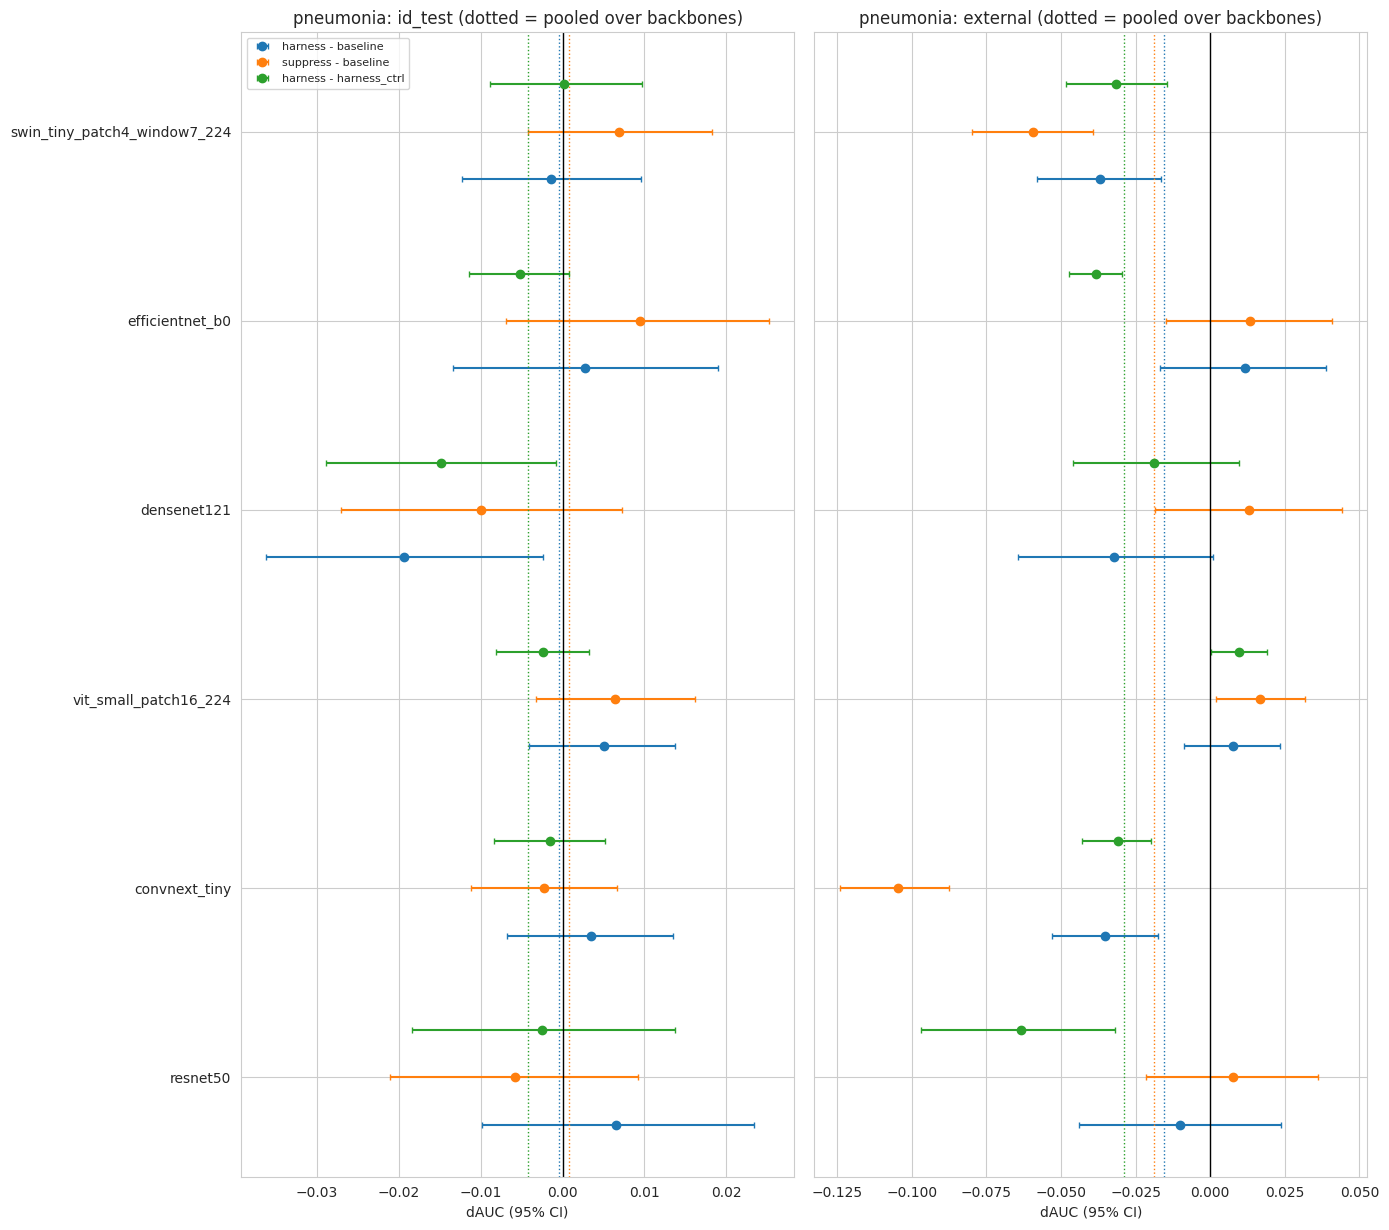

In [10]:
# =========================== 7. CROSS-BACKBONE AGGREGATION ===========================
# Reads the per-backbone files written by Section 6 from this session AND from any other session mounted under /kaggle/input
# (so a two-session split of BACKBONES is merged automatically). Writes table10/11/12 + the forest plot.
from scipy.stats import rankdata

def fast_auc(y, p):
    r = rankdata(p); n1 = int(y.sum()); n0 = len(y) - n1
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def holm_adj(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def find_per_backbone(prefix, ext):
    """{backbone: path} for files named <prefix>_<TAG>_<backbone>.<ext>; files from THIS session win over mounted ones."""
    out = {}
    pats = [f'/kaggle/input/**/{prefix}_{TAG}_*.{ext}', f'{RES}/{prefix}_{TAG}_*.{ext}']
    for pat in pats:                                  # later patterns overwrite earlier ones
        for p in sorted(glob.glob(pat, recursive=True)):
            bbn = os.path.basename(p)[len(f'{prefix}_{TAG}_'):-(len(ext) + 1)]
            out[bbn] = p
    return out

main_f, delt_f, pred_f = find_per_backbone('table2_main', 'csv'), find_per_backbone('table2b_deltas', 'csv'), find_per_backbone('preds', 'npz')
fore_f, tg_f = find_per_backbone('table4_forensic_probes', 'csv'), find_per_backbone('table8_transfer_gap', 'csv')
iv_f = find_per_backbone('table13_intervention', 'csv')
AGG_BB = [b for b in BACKBONES + [x for x in main_f if x not in BACKBONES] if b in main_f and b in delt_f]
print('backbones found:', AGG_BB, '| missing:', [b for b in BACKBONES if b not in AGG_BB])
assert AGG_BB, 'no per-backbone result files found - run Section 6 first.'

# ---------- Table 10: per-backbone summary of the arm effects (dAUC vs baseline, paired bootstrap, Holm over each backbone) ----------
rows = []
for b in AGG_BB:
    m = pd.read_csv(main_f[b]); d = pd.read_csv(delt_f[b])
    for ev in ('id_test', 'external'):
        k = 'te' if ev == 'id_test' else 'ex'
        base = m[(m.arm == 'baseline') & (m['eval'] == k)].iloc[0]
        for comp in ('harness - baseline', 'harness - harness_ctrl', 'suppress - baseline', 'aug - baseline', 'aug_strong - baseline', 'harness_brisque - baseline'):
            r = d[(d['eval'] == ev) & (d.comparison == comp)]
            if len(r):
                r = r.iloc[0]
                rows.append({'backbone': b, 'eval': ev, 'baseline_AUC': base.AUC_ens, 'comparison': comp, 'dAUC': r.dAUC, 'CI_lo': r.CI_lo,
                             'CI_hi': r.CI_hi, 'p_holm_within_backbone': r.p_holm, 'seeds_same_sign': f'{int(r.seeds_same_sign)}/{int(r.n_seeds)}'})
t10 = pd.DataFrame(rows); t10.to_csv(f'{RES}/table10_per_backbone_{TAG}.csv', index=False)
print('--- Table 10: arm effect on AUC for every backbone ---')
print(t10.pivot_table(index='backbone', columns=['comparison', 'eval'], values='dAUC').round(3).to_string())

# ---------- Table 11: architecture-pooled effects. Bootstrap resamples the SAME test images for every backbone (backbones share the test set) ----------
PZ = {b: np.load(pred_f[b]) for b in AGG_BB if b in pred_f}
def pooled(comp, k, n=1000, seed=5):
    a, bsl = comp.split(' - ')
    bbs = [b for b in PZ if f'p_{a}_{k}' in PZ[b] and f'p_{bsl}_{k}' in PZ[b]]
    if len(bbs) < 2: return None
    y = PZ[bbs[0]]['y_id' if k == 'te' else 'y_ex']
    assert all((PZ[b]['y_id' if k == 'te' else 'y_ex'] == y).all() for b in bbs), 'backbones were evaluated on different test sets'
    rng = np.random.default_rng(seed); D = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max(): continue
        D.append([fast_auc(y[idx], PZ[b][f'p_{a}_{k}'][idx]) - fast_auc(y[idx], PZ[b][f'p_{bsl}_{k}'][idx]) for b in bbs])
    D = np.asarray(D); pm = D.mean(1); lo, hi = np.percentile(pm, [2.5, 97.5])
    per = D.mean(0)
    return {'comparison': comp, 'eval': 'id_test' if k == 'te' else 'external', 'n_backbones': len(bbs), 'pooled_dAUC': pm.mean(), 'CI_lo': lo, 'CI_hi': hi,
            'p_value': min(1.0, max(2 * min((pm <= 0).mean(), (pm >= 0).mean()), 1 / (len(pm) + 1))),
            'backbones_positive': int((per > 0).sum()), 'backbones_sig_same_dir': int(sum((np.percentile(D[:, j], 2.5) > 0) if per[j] > 0 else (np.percentile(D[:, j], 97.5) < 0)
                                                                                         for j in range(len(bbs)) if per[j] != 0))}
POOL_COMPS = ('harness - baseline', 'harness - harness_ctrl', 'suppress - baseline', 'aug - baseline', 'harness - harness_zero', 'harness - harness_shuffle', 'harness_zero - baseline')
pr = [pooled(c, k) for c in POOL_COMPS for k in ('te', 'ex')]   # (aug arms exist for 1 backbone -> None)
t11 = pd.DataFrame([r for r in pr if r]); 
if len(t11):
    t11['p_holm'] = holm_adj(t11.p_value.values)
    print('--- Table 11: effect pooled over backbones (mean dAUC; shared-image bootstrap) ---'); print(t11.round(4).to_string(index=False))
    t11.to_csv(f'{RES}/table11_pooled_{TAG}.csv', index=False)

# ---------- Table 11b: SEED-AWARE pooled effects (bootstrap resamples test images AND training seeds; same draw for every backbone) ----------
def pooled_seedaware(comp, k, n=600, seed=9):
    a_, b_ = comp.split(' - ')
    bbs = [b for b in PZ if all(any(f'ps_{m}_{s}_{k}' in PZ[b] for s in SEEDS) for m in (a_, b_))]
    if len(bbs) < 2: return None
    seeds_all = [s for s in SEEDS if all(f'ps_{m}_{s}_{k}' in PZ[b] for b in bbs for m in (a_, b_))]
    if len(seeds_all) < 2: return None
    y = PZ[bbs[0]]['y_id' if k == 'te' else 'y_ex']; rng = np.random.default_rng(seed); D = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y)); ss = rng.choice(seeds_all, len(seeds_all), replace=True)
        if y[idx].min() == y[idx].max(): continue
        row = []
        for b in bbs:
            pa = np.mean([PZ[b][f'ps_{a_}_{s}_{k}'] for s in ss], axis=0); pb_ = np.mean([PZ[b][f'ps_{b_}_{s}_{k}'] for s in ss], axis=0)
            row.append(fast_auc(y[idx], pa[idx]) - fast_auc(y[idx], pb_[idx]))
        D.append(row)
    D = np.asarray(D); pm = D.mean(1); lo, hi = np.percentile(pm, [2.5, 97.5])
    return {'comparison': comp, 'eval': 'id_test' if k == 'te' else 'external', 'n_backbones': len(bbs), 'n_seeds': len(seeds_all), 'pooled_dAUC': pm.mean(), 'CI_lo': lo, 'CI_hi': hi,
            'p_value': min(1.0, max(2 * min((pm <= 0).mean(), (pm >= 0).mean()), 1 / (len(pm) + 1)))}
prs = [pooled_seedaware(c, k) for c in POOL_COMPS for k in ('te', 'ex')]
t11b = pd.DataFrame([r for r in prs if r])
if len(t11b):
    t11b['p_holm'] = holm_adj(t11b.p_value.values)
    print('--- Table 11b: effect pooled over backbones, SEED-AWARE bootstrap (images + seeds) - the CI to quote in the paper ---'); print(t11b.round(4).to_string(index=False))
    t11b.to_csv(f'{RES}/table11b_pooled_seedaware_{TAG}.csv', index=False)

# ---------- Table 12: does suppress remove information, per backbone? (suppress - baseline in the forensic probes) ----------
frows = []
for b in AGG_BB:
    if b not in fore_f: continue
    f = pd.read_csv(fore_f[b], index_col=0)
    for col in [c for c in f.columns if c.endswith('_mean') and (c.startswith('bucket_acc') or c.startswith('R2_BRISQUE') or c.startswith('domain_acc'))]:
        if 'suppress' in f.index and 'baseline' in f.index:
            frows.append({'backbone': b, 'probe': col[:-5], 'baseline': f.loc['baseline', col], 'suppress': f.loc['suppress', col],
                          'delta(suppress-baseline)': f.loc['suppress', col] - f.loc['baseline', col]})
t12 = pd.DataFrame(frows)
if len(t12):
    t12.to_csv(f'{RES}/table12_suppress_forensics_{TAG}.csv', index=False)
    print('--- Table 12: forensic probes, suppress vs baseline (negative = information removed) ---')
    print(t12.pivot_table(index='backbone', columns='probe', values='delta(suppress-baseline)').round(3).to_string())

# ---------- Table 13 (merged): test-time intervention on the degradation vector ----------
if iv_f:
    t13 = pd.concat([pd.read_csv(iv_f[b]).assign(backbone=b) for b in AGG_BB if b in iv_f], ignore_index=True)
    t13.to_csv(f'{RES}/table13_intervention_all_{TAG}.csv', index=False)
    print('--- Table 13: AUC drop when the degradation vector is zeroed / shuffled at test time (harness arm) ---')
    print(t13[t13.arm == 'harness'].pivot_table(index='backbone', columns=['eval', 'intervention'], values='drop(real-intervened)').round(4).to_string())

# ---------- Fig 8: forest plot of dAUC with 95% CI, one row per backbone ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(AGG_BB) * 3 + 2.5), sharey=True)
col = {'harness - baseline': '#1f77b4', 'suppress - baseline': '#ff7f0e', 'harness - harness_ctrl': '#2ca02c'}
for ax, ev in zip(axes, ('id_test', 'external')):
    for j, comp in enumerate(col):
        d = t10[(t10['eval'] == ev) & (t10.comparison == comp)].set_index('backbone').reindex(AGG_BB)
        ypos = np.arange(len(AGG_BB)) + (j - 1) * 0.25
        ax.errorbar(d.dAUC, ypos, xerr=[np.clip(d.dAUC - d.CI_lo, 0, None), np.clip(d.CI_hi - d.dAUC, 0, None)], fmt='o', color=col[comp], capsize=2, label=comp)
        if len(t11):
            p = t11[(t11['eval'] == ev) & (t11.comparison == comp)]
            if len(p): ax.axvline(p.pooled_dAUC.iloc[0], color=col[comp], ls=':', lw=1)
    ax.axvline(0, c='k', lw=1); ax.set_yticks(np.arange(len(AGG_BB))); ax.set_yticklabels(AGG_BB)
    ax.set_title(f'{TASK}: {ev} (dotted = pooled over backbones)'); ax.set_xlabel('dAUC (95% CI)')
axes[0].legend(fontsize=8, loc='best'); plt.tight_layout(); plt.savefig(f'{RES}/fig8_forest_backbones_{TAG}.png', dpi=200); plt.show()


## 8. Combined decision-rule analysis: fundus vs CXR, per backbone and pooled (needs the fundus notebook output as an input)

fundus backbones found: ['convnext_tiny', 'densenet121', 'efficientnet_b0', 'resnet50', 'swin_tiny_patch4_window7_224', 'vit_small_patch16_224'] | common with this notebook: ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224']
--- Table 9: difference-in-differences. gap = dAUC(external) - dAUC(ID); DiD = fundus gap - CXR gap. Holm over the pooled tests only. ---
arm_vs_baseline                     backbone  fundus_gap  cxr_gap     DiD   CI_lo  CI_hi  p_value  p_holm
        harness                     resnet50      0.0290  -0.0166  0.0457  0.0035 0.0878   0.0360     NaN
        harness                convnext_tiny      0.0028  -0.0384  0.0413  0.0182 0.0629   0.0010     NaN
        harness        vit_small_patch16_224      0.0162   0.0027  0.0135 -0.0059 0.0342   0.1960     NaN
        harness                  densenet121      0.0211  -0.0125  0.0336 -0.0053 0.0701   0.0900     NaN
        harness              efficien

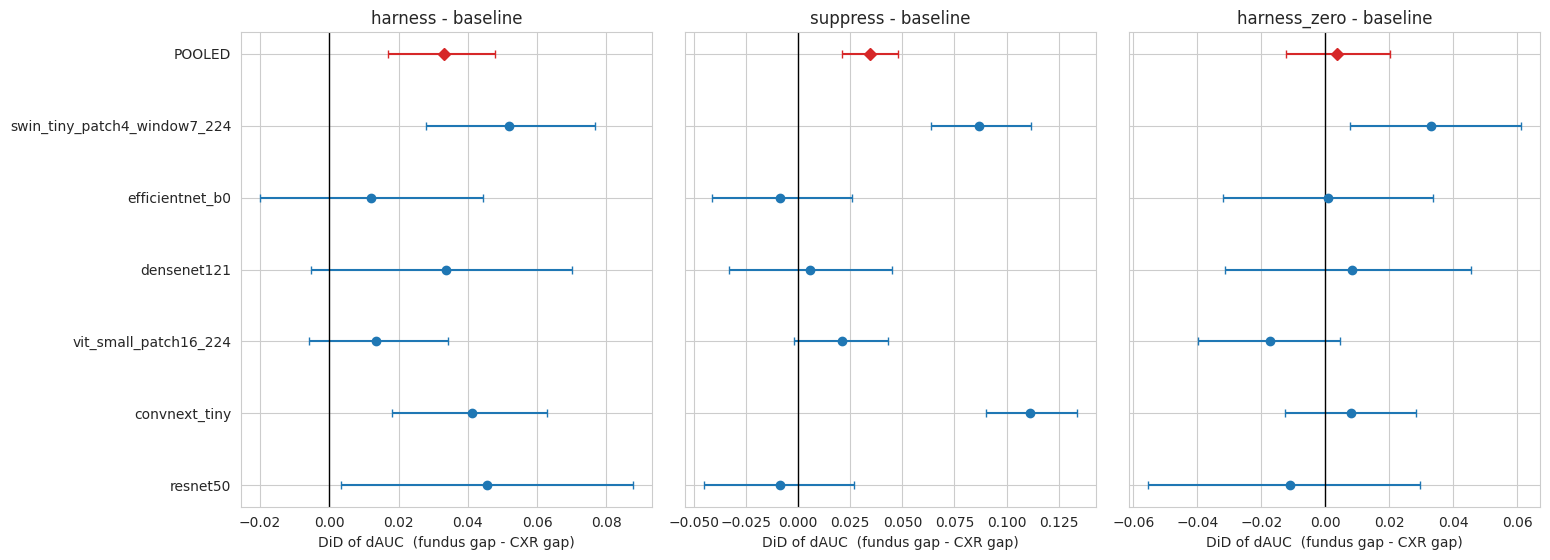

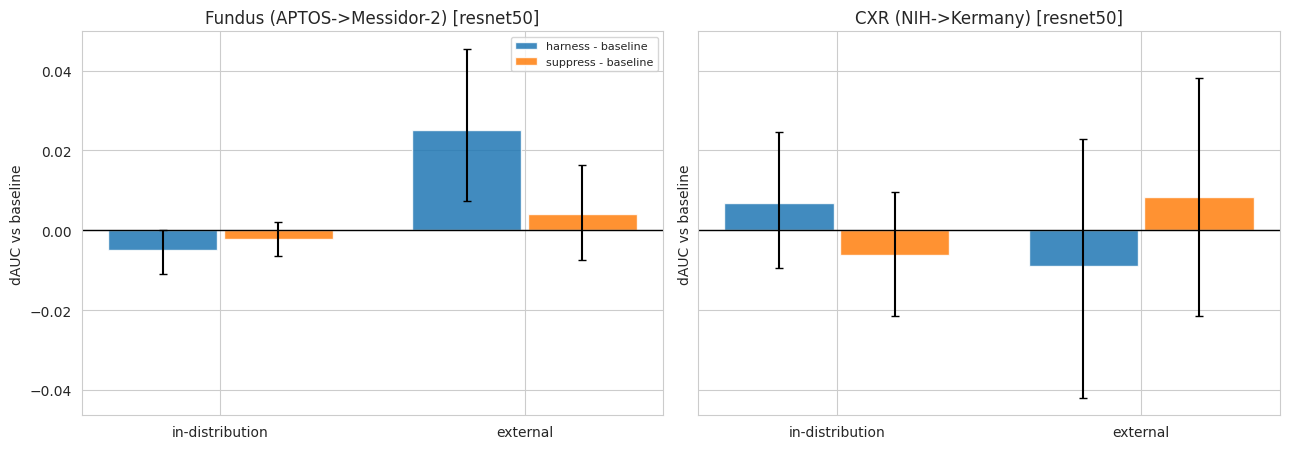

--- Table 15: test-time-intervention contrast (drop_fundus - drop_cxr, external sets). Prediction: > 0. Holm over {zero, shuffle} pooled tests. ---
intervention                     backbone  drop_fundus  drop_cxr  contrast(fundus-cxr)   CI_lo  CI_hi  p_value  p_holm
        zero                     resnet50       0.0142   -0.0347                0.0489  0.0175 0.0793   0.0020     NaN
        zero                convnext_tiny       0.0032   -0.0248                0.0279  0.0160 0.0395   0.0010     NaN
        zero        vit_small_patch16_224       0.0096   -0.0185                0.0280  0.0174 0.0380   0.0010     NaN
        zero                  densenet121       0.0054   -0.0172                0.0225  0.0101 0.0346   0.0010     NaN
        zero              efficientnet_b0       0.0009   -0.0097                0.0106  0.0056 0.0162   0.0010     NaN
        zero swin_tiny_patch4_window7_224       0.0069   -0.0072                0.0141  0.0035 0.0242   0.0140     NaN
        zero       

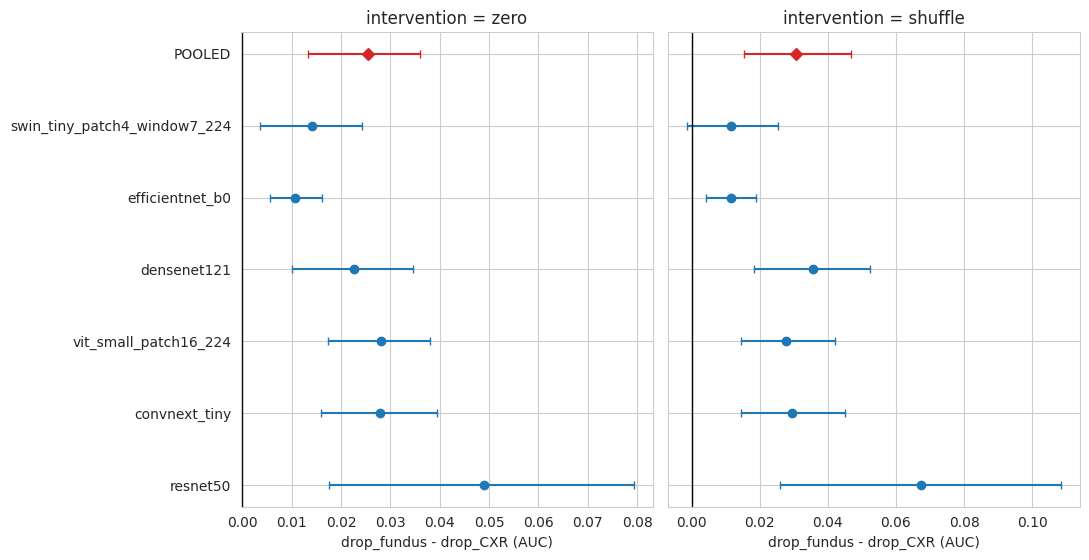

In [11]:
# ---------- 8. Combined decision-rule analysis: fundus (biomarker-like) vs CXR (shortcut-like), per backbone and pooled ----------
# Needs the OUTPUT of the fundus notebook(s) mounted as input (files preds_fundus_<backbone>.npz). Uses fast_auc / holm_adj from Section 7.
FP = {}
for p in sorted(glob.glob('/kaggle/input/**/preds_fundus_*.npz', recursive=True)):
    FP[os.path.basename(p)[len('preds_fundus_'):-4]] = p
COMMON = [b for b in AGG_BB if b in FP and b in PZ]
print('fundus backbones found:', list(FP), '| common with this notebook:', COMMON)
if not COMMON:
    print('No fundus outputs found under /kaggle/input. Commit the fundus notebook, add its OUTPUT as an input here, then re-run this cell.')
else:
    ZF = {b: np.load(FP[b]) for b in COMMON}
    ZC = {b: PZ[b] for b in COMMON}
    ARMS_CMP = [a for a in ('harness', 'suppress', 'aug', 'harness_zero') if all(f'p_{a}_te' in ZF[b] and f'p_{a}_te' in ZC[b] for b in COMMON)]
    rng = np.random.default_rng(11); N_BOOT = 1000
    # per draw: resample the fundus ID/ext images and the CXR ID/ext images ONCE, evaluate all backbones/arms on those SAME images
    draws = {(a, b): [] for a in ARMS_CMP for b in COMMON}; gf_all, gc_all = {(a, b): [] for a in ARMS_CMP for b in COMMON}, {(a, b): [] for a in ARMS_CMP for b in COMMON}
    yfi, yfe, yci, yce = ZF[COMMON[0]]['y_id'], ZF[COMMON[0]]['y_ex'], ZC[COMMON[0]]['y_id'], ZC[COMMON[0]]['y_ex']
    for _ in range(N_BOOT):
        ix = [rng.integers(0, len(y), len(y)) for y in (yfi, yfe, yci, yce)]
        if any(yy[i].min() == yy[i].max() for yy, i in zip((yfi, yfe, yci, yce), ix)): continue
        for b in COMMON:
            def dgap(Z, yi, ye, i_, e_, a):
                d_id = fast_auc(yi[i_], Z[f'p_{a}_te'][i_]) - fast_auc(yi[i_], Z['p_baseline_te'][i_])
                d_ex = fast_auc(ye[e_], Z[f'p_{a}_ex'][e_]) - fast_auc(ye[e_], Z['p_baseline_ex'][e_])
                return d_ex - d_id
            for a in ARMS_CMP:
                gf = dgap(ZF[b], yfi, yfe, ix[0], ix[1], a); gc = dgap(ZC[b], yci, yce, ix[2], ix[3], a)
                gf_all[(a, b)].append(gf); gc_all[(a, b)].append(gc); draws[(a, b)].append(gf - gc)
    rows = []
    for a in ARMS_CMP:
        M = np.array([draws[(a, b)] for b in COMMON])           # backbones x draws
        for j, b in enumerate(COMMON):
            v = M[j]; lo, hi = np.percentile(v, [2.5, 97.5])
            rows.append({'arm_vs_baseline': a, 'backbone': b, 'fundus_gap': np.mean(gf_all[(a, b)]), 'cxr_gap': np.mean(gc_all[(a, b)]),
                         'DiD': v.mean(), 'CI_lo': lo, 'CI_hi': hi, 'p_value': min(1.0, max(2 * min((v <= 0).mean(), (v >= 0).mean()), 1 / (len(v) + 1)))})
        v = M.mean(0); lo, hi = np.percentile(v, [2.5, 97.5])
        rows.append({'arm_vs_baseline': a, 'backbone': 'POOLED', 'fundus_gap': np.mean([np.mean(gf_all[(a, b)]) for b in COMMON]),
                     'cxr_gap': np.mean([np.mean(gc_all[(a, b)]) for b in COMMON]), 'DiD': v.mean(), 'CI_lo': lo, 'CI_hi': hi,
                     'p_value': min(1.0, max(2 * min((v <= 0).mean(), (v >= 0).mean()), 1 / (len(v) + 1)))})
    did = pd.DataFrame(rows); did['p_holm'] = np.nan
    did.loc[did.backbone == 'POOLED', 'p_holm'] = holm_adj(did[did.backbone == 'POOLED'].p_value.values)   # primary tests = pooled-over-backbone, one per arm
    print('--- Table 9: difference-in-differences. gap = dAUC(external) - dAUC(ID); DiD = fundus gap - CXR gap. Holm over the pooled tests only. ---')
    print(did.to_string(index=False, float_format=lambda v: f'{v:.4f}')); did.to_csv(f'{RES}/table9_did.csv', index=False)
    print('sign agreement with the pooled DiD:', {a: int((np.sign(did[(did.arm_vs_baseline == a) & (did.backbone != 'POOLED')].DiD) == np.sign(did[(did.arm_vs_baseline == a) & (did.backbone == 'POOLED')].DiD.iloc[0])).sum()) for a in ARMS_CMP}, 'of', len(COMMON), 'backbones')

    fig, axes = plt.subplots(1, len(ARMS_CMP), figsize=(5.2 * len(ARMS_CMP), 0.5 * (len(COMMON) + 1) + 2.2), sharey=True, squeeze=False)
    for ax, a in zip(axes[0], ARMS_CMP):
        d = did[did.arm_vs_baseline == a].set_index('backbone').reindex(COMMON + ['POOLED'])
        ypos = np.arange(len(d)); nb_ = len(COMMON)
        xe = np.vstack([np.clip((d.DiD - d.CI_lo).values, 0, None), np.clip((d.CI_hi - d.DiD).values, 0, None)])
        ax.errorbar(d.DiD.values[:nb_], ypos[:nb_], xerr=xe[:, :nb_], fmt='o', capsize=3, color='#1f77b4')
        ax.errorbar(d.DiD.values[nb_:], ypos[nb_:], xerr=xe[:, nb_:], fmt='D', capsize=3, color='#d62728', label='pooled')
        ax.axvline(0, c='k', lw=1); ax.set_yticks(ypos); ax.set_yticklabels(list(d.index)); ax.set_title(f'{a} - baseline'); ax.set_xlabel('DiD of dAUC  (fundus gap - CXR gap)')
    plt.tight_layout(); plt.savefig(f'{RES}/fig6_decision_rule_did.png', dpi=200); plt.show()

    # the original side-by-side figure for the primary backbone (ResNet-50 if present)
    pb = 'resnet50' if 'resnet50' in COMMON else COMMON[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    for ax, (nm, Z) in zip(axes, (('Fundus (APTOS->Messidor-2)', ZF[pb]), ('CXR (NIH->Kermany)', ZC[pb]))):
        for off, a, c in ((-0.19, 'harness', '#1f77b4'), (0.19, 'suppress', '#ff7f0e')):
            vals, los, his = [], [], []
            for k, yk in (('te', 'y_id'), ('ex', 'y_ex')):
                y = Z[yk]; r_ = np.random.default_rng(3); dd = []
                for _ in range(500):
                    i_ = r_.integers(0, len(y), len(y))
                    if y[i_].min() == y[i_].max(): continue
                    dd.append(fast_auc(y[i_], Z[f'p_{a}_{k}'][i_]) - fast_auc(y[i_], Z[f'p_baseline_{k}'][i_]))
                vals.append(np.mean(dd)); los.append(np.percentile(dd, 2.5)); his.append(np.percentile(dd, 97.5))
            vals, los, his = map(np.array, (vals, los, his))
            ax.bar(np.arange(2) + off, vals, 0.36, yerr=[np.clip(vals - los, 0, None), np.clip(his - vals, 0, None)], capsize=3, label=f'{a} - baseline', color=c, alpha=0.85)
        ax.axhline(0, c='k', lw=1); ax.set_xticks([0, 1]); ax.set_xticklabels(['in-distribution', 'external']); ax.set_title(f'{nm} [{pb}]'); ax.set_ylabel('dAUC vs baseline')
    axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{RES}/fig6b_decision_rule_{pb}.png', dpi=200); plt.show()

    # ---------- Table 15 (PRE-SPECIFIED PRIMARY TEST of C3): does the test-time intervention drop have OPPOSITE sign in the two datasets? ----------
    # drop = AUC(real degradation vector) - AUC(vector zeroed), on the EXTERNAL set. Prediction written down before the v5 run:
    #   fundus (biomarker-like): drop > 0     CXR (shortcut-like): drop < 0     =>  contrast = drop_fundus - drop_cxr > 0.
    # Bootstrap resamples the images of both external sets (same draw for every backbone); pooled = mean over backbones; Holm over {zero, shuffle}.
    if all('p_harness_zero_ex' in ZF[b] and 'p_harness_zero_ex' in ZC[b] for b in COMMON):
        rows15, rng15 = [], np.random.default_rng(21)
        IV = ('zero', 'shuffle')
        D15 = {(dm, b): [] for dm in IV for b in COMMON}; DF = {(dm, b): [] for dm in IV for b in COMMON}; DC = {(dm, b): [] for dm in IV for b in COMMON}
        for _ in range(N_BOOT):
            i_f, i_c = rng15.integers(0, len(yfe), len(yfe)), rng15.integers(0, len(yce), len(yce))
            if yfe[i_f].min() == yfe[i_f].max() or yce[i_c].min() == yce[i_c].max(): continue
            for b in COMMON:
                for dm in IV:
                    df_ = fast_auc(yfe[i_f], ZF[b]['p_harness_ex'][i_f]) - fast_auc(yfe[i_f], ZF[b][f'p_harness_{dm}_ex'][i_f])
                    dc_ = fast_auc(yce[i_c], ZC[b]['p_harness_ex'][i_c]) - fast_auc(yce[i_c], ZC[b][f'p_harness_{dm}_ex'][i_c])
                    DF[(dm, b)].append(df_); DC[(dm, b)].append(dc_); D15[(dm, b)].append(df_ - dc_)
        for dm in IV:
            for b in COMMON + ['POOLED']:
                if b == 'POOLED':
                    v = np.mean([D15[(dm, c)] for c in COMMON], axis=0); f_ = np.mean([np.mean(DF[(dm, c)]) for c in COMMON]); c_ = np.mean([np.mean(DC[(dm, c)]) for c in COMMON])
                else:
                    v = np.asarray(D15[(dm, b)]); f_, c_ = np.mean(DF[(dm, b)]), np.mean(DC[(dm, b)])
                lo, hi = np.percentile(v, [2.5, 97.5])
                rows15.append({'intervention': dm, 'backbone': b, 'drop_fundus': f_, 'drop_cxr': c_, 'contrast(fundus-cxr)': v.mean(), 'CI_lo': lo, 'CI_hi': hi,
                               'p_value': min(1.0, max(2 * min((v <= 0).mean(), (v >= 0).mean()), 1 / (len(v) + 1)))})
        t15 = pd.DataFrame(rows15); t15['p_holm'] = np.nan
        t15.loc[t15.backbone == 'POOLED', 'p_holm'] = holm_adj(t15[t15.backbone == 'POOLED'].p_value.values)
        print('--- Table 15: test-time-intervention contrast (drop_fundus - drop_cxr, external sets). Prediction: > 0. Holm over {zero, shuffle} pooled tests. ---')
        print(t15.to_string(index=False, float_format=lambda v: f'{v:.4f}')); t15.to_csv(f'{RES}/table15_intervention_contrast.csv', index=False)
        print('backbones with contrast > 0:', {dm: int((t15[(t15.intervention == dm) & (t15.backbone != 'POOLED')]['contrast(fundus-cxr)'] > 0).sum()) for dm in IV}, 'of', len(COMMON))
        fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * (len(COMMON) + 1) + 2.2), sharey=True)
        for ax, dm in zip(axes, IV):
            d = t15[t15.intervention == dm].set_index('backbone').reindex(COMMON + ['POOLED']); yp = np.arange(len(d)); nb_ = len(COMMON)
            xe = np.vstack([np.clip((d['contrast(fundus-cxr)'] - d.CI_lo).values, 0, None), np.clip((d.CI_hi - d['contrast(fundus-cxr)']).values, 0, None)])
            ax.errorbar(d['contrast(fundus-cxr)'].values[:nb_], yp[:nb_], xerr=xe[:, :nb_], fmt='o', capsize=3, color='#1f77b4')
            ax.errorbar(d['contrast(fundus-cxr)'].values[nb_:], yp[nb_:], xerr=xe[:, nb_:], fmt='D', capsize=3, color='#d62728', label='pooled')
            ax.axvline(0, c='k', lw=1); ax.set_yticks(yp); ax.set_yticklabels(list(d.index)); ax.set_title(f'intervention = {dm}'); ax.set_xlabel('drop_fundus - drop_CXR (AUC)')
        plt.tight_layout(); plt.savefig(f'{RES}/fig7_intervention_contrast.png', dpi=200); plt.show()
    else:
        print('Table 15 skipped: p_harness_zero_ex missing in the fundus or CXR preds (re-run both v5 notebooks).')


## 10. Bundle outputs

In [12]:
# ---- bundle everything for download + record the environment ----
import importlib.metadata as md
env = {'torch': torch.__version__, 'seeds': SEEDS, 'epochs': EPOCHS, 'backbones_evaluated_here': BBS_DONE, 'arms_for': ARMS_FOR,
       'lr_bb': LR_BB, 'SMOKE': SMOKE, 'tag': TAG, 'runtime_h': round((time.time() - T0) / 3600, 2)}
for pk in ('timm', 'pyiqa', 'scikit-learn', 'numpy', 'pandas'):
    try: env[pk] = md.version(pk)
    except Exception: pass
json.dump(env, open(f'{RES}/env_{TAG}.json', 'w'), indent=1)
shutil.copy(f'{FEAT}/all_degradation.csv', f'{RES}/all_degradation_{TAG}.csv')
zp = shutil.make_archive(f'{TOP}/results_{TAG}{"_smoke" if SMOKE else ""}', 'zip', RES)
print('ALL DONE. Download:', zp, '| env:', env)


ALL DONE. Download: /kaggle/working/results_cxr.zip | env: {'torch': '2.11.0+cu128', 'seeds': [42, 7, 2024, 11, 99], 'epochs': 15, 'backbones_evaluated_here': ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224'], 'arms_for': {'resnet50': ['baseline', 'harness', 'harness_ctrl', 'suppress', 'aug', 'aug_strong', 'harness_brisque'], 'convnext_tiny': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'vit_small_patch16_224': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'densenet121': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'efficientnet_b0': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'swin_tiny_patch4_window7_224': ['baseline', 'harness', 'harness_ctrl', 'suppress']}, 'lr_bb': {'resnet50': 3e-05, 'convnext_tiny': 3e-05, 'vit_small_patch16_224': 3e-05, 'densenet121': 5e-05, 'efficientnet_b0': 0.0001, 'swin_tiny_patch4_window7_224': 3e-05}, 'SMOKE': False, 'tag': 'cxr', 'runtime_h': 9.98, 'tim